In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import tensorflow as tf


from tensorflow.keras import layers, models
from sklearn.model_selection import TimeSeriesSplit
import json
from itertools import product
from tensorflow.keras.layers import Input, LSTM, Attention, Dense
from tensorflow.keras.models import Model
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from tensorflow.keras.metrics import RootMeanSquaredError
import time


2026-03-02 16:11:03.119812: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772467863.341325      13 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772467863.405731      13 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


***X CLASS FLARE TRAINING -----------------------------------------------------***

In [2]:
#FOR CSV
# re opening the xflare instances time series collection files
#dataframe
xflareinstances_reloaded = pd.read_csv("/kaggle/input/mflareinstances-6col-cleaned/mflareinstances_FULLCOL.csv")
#converting the json formatted strings into python list (.loads) into a numpy array (.array) and finally does it on all elements in the input/output (.apply)
#xflareinstances_reloaded["input"/"output"] is a pandas series 
inputxflareinstances = xflareinstances_reloaded["input"].apply(lambda x: np.array(json.loads(x)))
outputxflareinstances = xflareinstances_reloaded["output"].apply(lambda x: np.array(json.loads(x)))

#stack into a 3d array for lstm use
#.to_numpy makes it a 1d array array([array[], array[], ...]), N separate arrays of (L, F)
#.stack makes it (N, L, F), adds another dimension into a 3d array!!!!
X = np.stack(inputxflareinstances.to_numpy())
Y = np.stack(outputxflareinstances.to_numpy()) 

print(X.shape)
print(Y.shape)

(311, 15, 8)
(311, 5, 1)


In [3]:
#removing xr_qual and is_tmfi
#ONLY RUN THIS ONCE OTHERWISE IT WILL KEEP ON DELETING
#removing last two elements 
X = X[:, :, 5:6]
lastfeatureindex = 0
X.shape

(311, 15, 1)

In [4]:
#shuffle the data 
shuffled_indices = np.random.permutation(len(X))

# 3. Apply the *same* indices to both datasets
X = X[shuffled_indices]
Y = Y[shuffled_indices]

In [5]:
print("Y min/max:", Y.min(), Y.max())
print("Any negatives in Y?", np.any(Y < 0))
neg_mask = (Y < 0).any(axis=(1,2))   # True for samples with any negative future value
print("Number of samples with negatives:", neg_mask.sum())
neg_indices = np.where(neg_mask)[0]
print("First 10 negative sample indices:", neg_indices[:10])

Y min/max: -99999.0 9.3552e-05
Any negatives in Y? True
Number of samples with negatives: 4
First 10 negative sample indices: [  1  79 203 231]


In [6]:
print("X min/max:", X.min(), X.max())
print("Any negatives in X?", np.any(X < 0))
neg_mask = (X < 0).any(axis=(1,2))   # True for samples with any negative future value
print("Number of samples with negatives:", neg_mask.sum())
neg_indices = np.where(neg_mask)[0]
print("First 10 negative sample indices:", neg_indices[:10])

X min/max: 1.0138e-07 0.00021285
Any negatives in X? False
Number of samples with negatives: 0
First 10 negative sample indices: []


In [7]:
# Filter out all values where y is negative
mask = ~(Y < 0).any(axis=(1,2))
X = X[mask]
Y = Y[mask]
X.shape

(307, 15, 1)

In [8]:
# Chronological split (no shuffling for time series)
split = int(0.6 * len(X))
X_train, Y_train = X[:split], Y[:split]
X_oth,   Y_oth   = X[split:], Y[split:]
newsplit = int(0.75 * len(X_oth))
X_val,  Y_val    = X_oth[newsplit:], Y_oth[newsplit:]
X_test,  Y_test  = X_oth[:newsplit], Y_oth[:newsplit]
print(X_train.shape)
print(X_test.shape)
print(X_val.shape)

(184, 15, 1)
(92, 15, 1)
(31, 15, 1)


In [9]:
#features
F = 1
#length of input window
L = 15
#length of output window
H = 5

In [10]:
#checking to find any negatives! 
#should be false for the scaling to work well and not lose any information
np.any(X < 0)

False

In [11]:
#NEW LOG SCALER
#clip replaces all the negative values with 0, fine because no negatives
#computes log(1 + z), handles zeros and small values better than plain log
#same shape is maintained
X_log = np.log1p(np.clip(X, 0, None))

# 2. Scale features
#creating a scaler on the training section of the data -> using the logged version
#reshapes the dataset to be (rows*time steps, feature) cause time series doesn't work on scaling
x_scaler = StandardScaler().fit(X_log[:split].reshape(-1, F))

#implementing this scaler onto both the training and validation datasets
#avoids leakage, only has information on the training sets
#the dataset is re-reshaped into its original (n, l, f) form after it is scaled
X_train_s = x_scaler.transform(X_log[:split].reshape(-1, F)).reshape(X_train.shape)
X_val_s   = x_scaler.transform(X_log[split+newsplit:].reshape(-1, F)).reshape(X_val.shape)
X_test_s   = x_scaler.transform(X_log[split:split+newsplit].reshape(-1, F)).reshape(X_test.shape)

# 3. Log + scale targets
#doing basically the same thing but on the Y dataset
Y_train_tf = np.log1p(np.clip(Y_train, 0, None))

#keeping training and validation separate
Y_val_tf   = np.log1p(np.clip(Y_val,   0, None))
Y_test_tf   = np.log1p(np.clip(Y_test,   0, None))

y_scaler = StandardScaler().fit(Y_train_tf.reshape(-1,1))
Y_train_s = y_scaler.transform(Y_train_tf.reshape(-1,1)).reshape(Y_train.shape)
Y_val_s   = y_scaler.transform(Y_val_tf.reshape(-1,1)).reshape(Y_val.shape)
Y_test_s   = y_scaler.transform(Y_test_tf.reshape(-1,1)).reshape(Y_test.shape)

In [12]:
X_train_s.shape

(184, 15, 1)

In [13]:
#finding range to calculate rmse
Yrange = Y_train.max() - Y_train.min()
Yrange

9.321648e-05

In [14]:
def plot_encoder_gaussian_noise_sweep(
    x_seq,                      # shape (L, F) for ONE sequence
    sigmas=(0.0, 5e-8, 1e-7, 2e-7),
    n_samples=100,              # Monte Carlo samples per sigma
    feature_idx=0,              # which feature (0..F-1) to visualize
    time=None,                  # optional array shape (L,)
    log_scale=False,            # True if feature is flux and you want log y
    title="Effect of Gaussian Noise on Encoder Inputs",
    x_label="Time (12 minute cadences)",
    y_label="Feature value",
    save_path=None,
    dpi=300,
    seed=42
):
    """
    Visualize the effect of tf.keras.layers.GaussianNoise on encoder inputs.
    Matches your model behavior by sampling noise with training=True.

    Shows: clean curve + Monte Carlo band (5th-95th percentile) for each sigma.
    """
    x_seq = np.asarray(x_seq)
    assert x_seq.ndim == 2, "x_seq should be shape (L, F) for one time series window."
    L, F = x_seq.shape
    assert 0 <= feature_idx < F

    if time is None:
        time = np.arange(L)
    else:
        time = np.asarray(time)
        assert time.shape == (L,)

    # Styling: clean poster look (no top/right spines, readable fonts)
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": dpi,
        "savefig.dpi": dpi,
    })

    # Deterministic seeds (note: TF randomness can still vary across devices)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    # Prepare figure (2x2 if 4 sigmas; otherwise auto grid)
    n = len(sigmas)
    ncols = 2
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(10, 3.6 * nrows), sharex=True, sharey=True)
    axes = np.array(axes).reshape(-1)

    clean = x_seq[:, feature_idx]

    # For log scale, ensure positive values (GOES flux should be positive)
    if log_scale:
        eps = np.finfo(float).tiny
        clean_plot = np.clip(clean, eps, None)
    else:
        clean_plot = clean

    for ax, sigma in zip(axes, sigmas):
        # Build a GaussianNoise layer matching your model
        noise_layer = tf.keras.layers.GaussianNoise(stddev=sigma)

        # Sample noisy realizations exactly like training-time behavior
        # Shape: (n_samples, L, F)
        x_batch = np.repeat(x_seq[None, :, :], repeats=n_samples, axis=0).astype(np.float32)
        x_noisy = noise_layer(x_batch, training=True).numpy()

        noisy_feature = x_noisy[:, :, feature_idx]  # (n_samples, L)

        if log_scale:
            noisy_feature = np.clip(noisy_feature, eps, None)

        # Monte Carlo summary: median + 5-95% band (clean and poster-friendly)
        p05 = np.percentile(noisy_feature, 5, axis=0)
        p50 = np.percentile(noisy_feature, 50, axis=0)
        p95 = np.percentile(noisy_feature, 95, axis=0)

        # Plot clean line once per panel
        ax.plot(time, clean_plot, linewidth=2.2, label="Clean")

        # Plot band + median of noisy samples
        ax.fill_between(time, p05, p95, alpha=0.20, label="Noisy 5–95%")
        ax.plot(time, p50, linewidth=1.2, alpha=0.9, label="Noisy median")

        ax.text(
            0.03, 0.93,
            rf"$\sigma$ = {sigma:g}",
            transform=ax.transAxes,
            va="top"
        )

        if log_scale:
            ax.set_yscale("log")

    # Remove unused axes if sigmas not filling grid
    for j in range(len(sigmas), len(axes)):
        fig.delaxes(axes[j])

    # Labels
    for ax in fig.axes:
        ax.set_xlabel(x_label)
    for r in range(nrows):
        fig.axes[r * ncols].set_ylabel(y_label)

    fig.suptitle(title, y=0.98)

    # Single legend (prevents the messy legend pileup you got)
    handles, labels = fig.axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.94))

    fig.tight_layout(rect=[0, 0, 1, 0.92])

    if save_path:
        fig.savefig(save_path, bbox_inches="tight")
        print(f"Saved: {save_path}")

    return fig

2026-03-02 16:11:16.650521: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Saved: encoder_noise_sweep.png


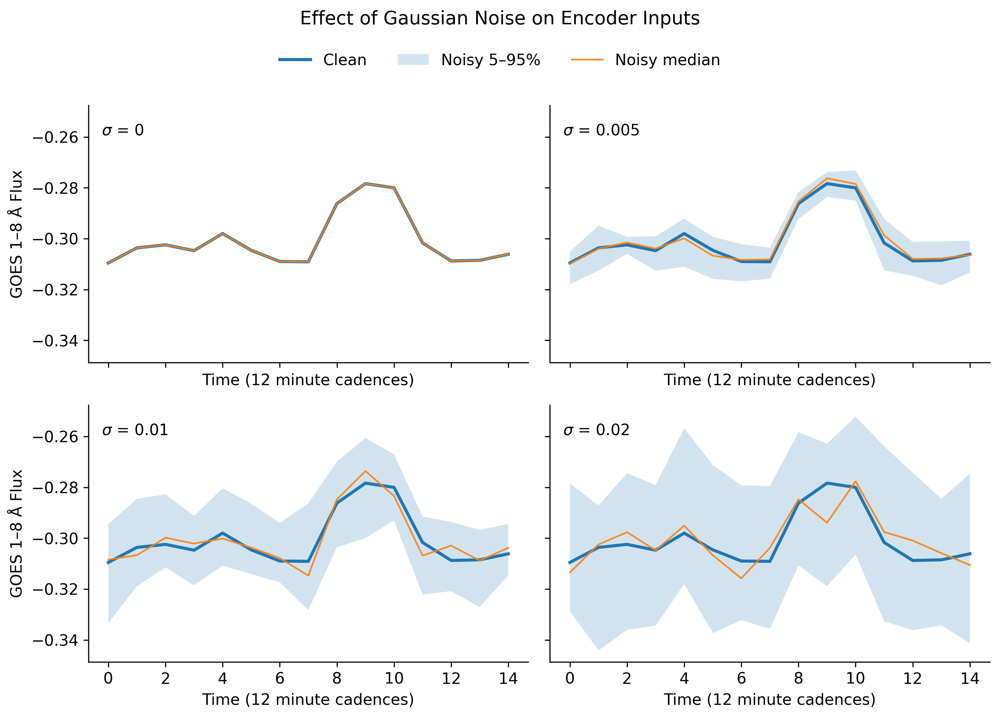

In [15]:
# x_seq is one encoder window of shape (L, F)
# Example: visualize feature 0 (maybe GOES flux) with log scale
plot_encoder_gaussian_noise_sweep(
    x_seq=X_train_s[0],
    sigmas=(0.0, 0.005, 0.01, 0.02),
    n_samples=15,
    feature_idx=0,
    time=np.arange(X_train_s[0].shape[0]),
    log_scale=False,  # set False if normalized features
    y_label="GOES 1–8 Å Flux",
    save_path="encoder_noise_sweep.png"
)
plt.show()

In [16]:
def plot_noise_error_overlay(
    x_seq,                      # (L, F) single encoder window
    sigmas=(0.005, 0.01, 0.02, 0.05),
    n_samples=200,
    feature_idx=0,
    time=None,
    show_clean=True,
    log_scale=False,            # for the underlying signal, not required for error
    title="Encoder Input Perturbation: |Noisy − Clean| vs Time",
    x_label="Time (12 minute cadences)",
    y_label="Absolute Error",
    save_path=None,
    dpi=300,
    seed=42
):
    """
    Single-panel overlay of noise-induced error for multiple sigmas.
    Uses tf.keras.layers.GaussianNoise(stddev=sigma) with training=True.
    """
    x_seq = np.asarray(x_seq)
    assert x_seq.ndim == 2, "x_seq must be (L, F)"
    L, F = x_seq.shape
    assert 0 <= feature_idx < F

    if time is None:
        time = np.arange(L)
    else:
        time = np.asarray(time)
        assert time.shape == (L,)

    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": dpi,
        "savefig.dpi": dpi,
    })

    np.random.seed(seed)
    tf.random.set_seed(seed)

    clean = x_seq[:, feature_idx].astype(np.float32)

    fig, ax = plt.subplots(1, 1, figsize=(10, 4.8))

    # Compute error envelopes for each sigma and overlay
    for sigma in sigmas:
        noise_layer = tf.keras.layers.GaussianNoise(stddev=sigma)

        x_batch = np.repeat(x_seq[None, :, :], repeats=n_samples, axis=0).astype(np.float32)
        x_noisy = noise_layer(x_batch, training=True).numpy()  # (N, L, F)

        noisy_feat = x_noisy[:, :, feature_idx]                # (N, L)
        abs_err = np.abs(noisy_feat - clean[None, :])          # (N, L)

        # Envelope summary
        p50 = np.percentile(abs_err, 50, axis=0)
        p90 = np.percentile(abs_err, 90, axis=0)

        # Shade 0→p90 (or p10→p90 if you prefer)
        ax.fill_between(time, 0, p90, alpha=0.18)
        ax.plot(time, p50, linewidth=2.0, label=rf"$\sigma$={sigma:g} (median |err|)")

    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

    # Optional: add clean signal on a second y-axis (looks sharp and avoids scale clash)
    if show_clean:
        ax2 = ax.twinx()
        clean_plot = clean
        if log_scale:
            eps = np.finfo(float).tiny
            clean_plot = np.clip(clean_plot, eps, None)
            ax2.set_yscale("log")
        ax2.plot(time, clean_plot, linewidth=2.2, alpha=0.75)
        ax2.set_ylabel("Clean signal")

        # Clean up extra spines
        ax2.spines["top"].set_visible(False)

    ax.legend(frameon=False, ncol=2)
    fig.tight_layout()

    if save_path:
        fig.savefig(save_path, bbox_inches="tight")
        print(f"Saved: {save_path}")

    return fig

Saved: noise_error_overlay.png


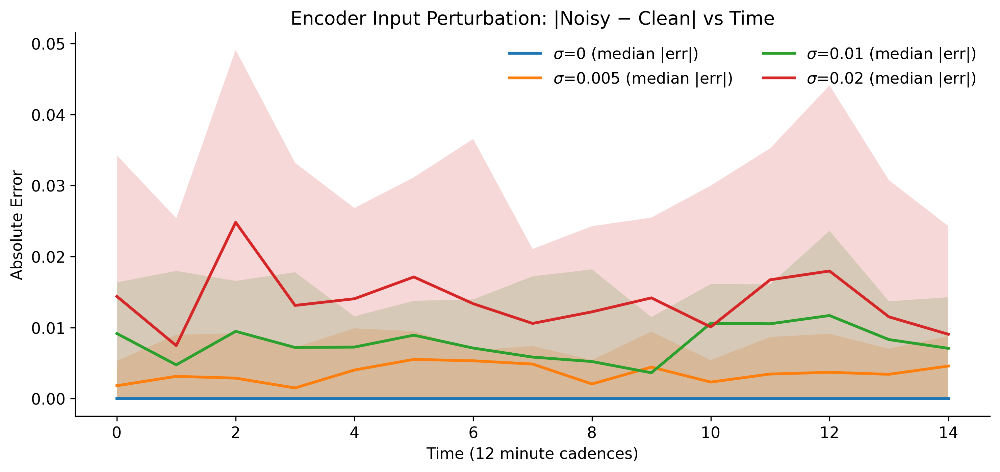

In [17]:
plot_noise_error_overlay(
    x_seq=X_train_s[0],
    sigmas=(0.0, 0.005, 0.01, 0.02),   # include 0.02 since it's your actual training sigma
    n_samples=15,
    feature_idx=0,
    time=np.arange(X_train_s[0].shape[0]),
    show_clean=False,
    log_scale=False,                  # True only if clean signal is raw positive flux
    save_path="noise_error_overlay.png"
)
plt.show()

In [18]:
#sequence-to-sequence LSTM auto-regressive model: output of one time step = inputs for next prediction
#Encoder LSTM → Bottleneck → RepeatVector → Decoder LSTM → Dense → Output sequence

#lstm_units: number of hidden neurons in lstm, more = more complex and tendency to overfit
def build_lstm_model(L, F, H, lstm_units=32, dropout=0.2, lr=1e-3):
    inp = layers.Input(shape=(L, F))
    #the encoder creates a hidden state (compressed hidden representation) starting from the first timestep and updates it with the addition of every new timestep
    #return sequences = false makes it so that the encoder only returns the final hidden state, not the ones prior during the process
    enc = layers.LSTM(lstm_units, return_sequences=False)(inp)
    #dropout to prevent overfitting
    enc = layers.Dropout(dropout)(enc)
    #crucial step, copies the hidden state H times (length of output vector), used as input for decoder
    rep = layers.RepeatVector(H)(enc)
    #looks at input sequence + hidden state, outputs hidden state for each of the H time steps which is then added to the next decoder input for prediction, since return sequence is true
    dec = layers.LSTM(lstm_units, return_sequences=True)(rep)
    dec = layers.Dropout(dropout)(dec)
    #output layer, applies dense layer to EACH timestep to predict one number (final output)
    out = layers.TimeDistributed(layers.Dense(1))(dec)
    #builds model
    model = models.Model(inp, out)
    #keras metrics run on the scaled, log-transformed data!!!!!!!
    model.compile(  
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.Huber(),
        metrics=["mae"]
    )
    return model


In [19]:
def build_lstm_teacher_forcing(L, F, H, lstm_units=32, dropout=0.2, lr=1e-3, sigma = 0.02):
    """
    L: encoder input length
    F: number of features in encoder input
    H: decoder output length (number of forecast steps)
    """

    # Encoder
    encoder_inputs = layers.Input(shape=(L, F), name="encoder_inputs")
    encoder_inputs_noisy = tf.keras.layers.GaussianNoise(stddev=sigma)(encoder_inputs)  # active only in training
    enc = layers.LSTM(lstm_units, return_sequences=True, return_state=True, name="encoder_lstm")
    encoder_outputs, state_h, state_c = enc(encoder_inputs_noisy)

    enc_dropout = layers.Dropout(dropout, name="encoder_dropout")(encoder_outputs)
    
    # We only use final states as initial state of decoder
    # Decoder
    # Here I assume your target at each step is a single scalar → shape (H, 1)
    decoder_inputs = layers.Input(shape=(H, 1), name="decoder_inputs")

    dec_lstm = layers.LSTM(
        lstm_units,
        return_sequences=True,
        return_state=True,
        name="decoder_lstm",
    )
    decoder_outputs, _, _ = dec_lstm(
        decoder_inputs,
        initial_state=[state_h, state_c]  # initialize with encoder states
    )

    attn_layer = layers.AdditiveAttention(name="attention")
    context_seq = attn_layer(
        [decoder_outputs, enc_dropout]
    )
    x = layers.Concatenate(axis=-1)([decoder_outputs, context_seq])

    dec_dropout = layers.Dropout(dropout, name="decoder_dropout")(x)

    # Output: one scalar per time step
    decoder_dense = layers.TimeDistributed(layers.Dense(1), name="output_dense")
    outputs = decoder_dense(dec_dropout)

    model = models.Model(
        inputs=[encoder_inputs, decoder_inputs],
        outputs=outputs,
        name="seq2seq_teacher_forcing",
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.Huber(),
        metrics=["mae"],
    )

    return model


In [20]:
def make_inference_models(trained_model, L, F, lstm_units=32, use_encoder_dropout=True):

    encoder_inputs = trained_model.inputs[0]
    encoder_lstm = trained_model.get_layer("encoder_lstm")

    # encoder_lstm outputs: (encoder_outputs_seq, state_h, state_c)
    encoder_outputs_seq, state_h_enc, state_c_enc = encoder_lstm.output

    if use_encoder_dropout:
        # Matches  training model because attention used enc_dropout
        encoder_seq_for_attention = trained_model.get_layer("encoder_dropout").output
    else:
        # raw encoder sequence output (still works, just slightly different)
        encoder_seq_for_attention = encoder_outputs_seq

    encoder_model = models.Model(
        inputs=encoder_inputs,
        outputs=[encoder_seq_for_attention, state_h_enc, state_c_enc],
        name="encoder_inference",
    )

    # inputs for one step
    dec_input = layers.Input(shape=(1, 1), name="dec_step_input")  
    dec_state_input_h = layers.Input(shape=(lstm_units,), name="dec_state_input_h")
    dec_state_input_c = layers.Input(shape=(lstm_units,), name="dec_state_input_c")
    enc_seq_input = layers.Input(shape=(L, lstm_units), name="enc_seq_input")  # for attention

    decoder_lstm = trained_model.get_layer("decoder_lstm")
    attn_layer = trained_model.get_layer("attention")
    output_dense = trained_model.get_layer("output_dense")  # TimeDistributed(Dense(1))

    # run decoder LSTM for one step
    dec_outputs, dec_state_h, dec_state_c = decoder_lstm(
        dec_input,
        initial_state=[dec_state_input_h, dec_state_input_c]
    )  # (batch, 1, lstm_units)

    # attention over encoder sequence
    context_seq = attn_layer([dec_outputs, enc_seq_input])  


    x = layers.Concatenate(axis=-1, name="dec_ctx_concat")([dec_outputs, context_seq])  # (batch, 1, 2*lstm_units)


    # final prediction
    step_output = output_dense(x) 

    decoder_model = models.Model(
        inputs=[dec_input, dec_state_input_h, dec_state_input_c, enc_seq_input],
        outputs=[step_output, dec_state_h, dec_state_c],
        name="decoder_inference",
    )

    return encoder_model, decoder_model

In [21]:
def _seed_from_raw_value_as_y_space(raw_value, y_scaler, use_log1p=True):
    """
    Convert a raw value (original units) into the same scaled space as Y_train_s.
    Returns shape (1, 1, 1).
    """
    raw_value = float(raw_value)
    y_val = np.log1p(raw_value) if use_log1p else raw_value
    y_val = np.array([[y_val]], dtype=np.float32)            # (1, 1)
    y_val_s = y_scaler.transform(y_val).astype(np.float32)   # (1, 1)
    return y_val_s.reshape(1, 1, 1)                          # (1, 1, 1)


def predict_autoregressive(
    encoder_model,
    decoder_model,
    X_s,
    H,
    start_token="zeros",
    start_from_last_feature_index=None,
    # NEW: provide raw X so we can seed correctly
    X_raw=None,
    last_x_raw_feature_index=None,
    y_scaler=None,
    use_log1p=True,
):
    """
    start_token options:
      - "zeros": seed decoder with 0 in Y-scaled space
      - "last_x": seed with last value from X_s (already scaled with x_scaler) NOT recommended
      - "last_x_raw": seed with last value from X_raw, then convert to Y-scaled space using y_scaler (recommended if X contains target variable in raw units)
    """

    N, L, F = X_s.shape
    preds = np.zeros((N, H, 1), dtype=np.float32)

    if start_token == "last_x_raw":
        if X_raw is None or y_scaler is None or last_x_raw_feature_index is None:
            raise ValueError(
                "For start_token='last_x_raw', you must provide X_raw, last_x_raw_feature_index, and y_scaler."
            )
        X_raw = np.asarray(X_raw)
        if X_raw.shape[0] != N or X_raw.shape[1] != L:
            raise ValueError("X_raw must have shape (N, L, F_raw) aligned with X_s samples and window length.")

    for i in range(N):
        x_enc_s = X_s[i:i+1]  # (1, L, F)

        # Encode once
        enc_seq, state_h, state_c = encoder_model.predict(x_enc_s, verbose=0)

        # Initialize decoder input y_t
        if start_token == "zeros":
            y_t = np.zeros((1, 1, 1), dtype=np.float32)

        elif start_token == "last_x":
            if start_from_last_feature_index is None:
                raise ValueError("start_from_last_feature_index must be set when start_token='last_x'")
            last_val = x_enc_s[0, -1, start_from_last_feature_index]  # this is X-scaled space
            y_t = np.array([[[last_val]]], dtype=np.float32)

        elif start_token == "last_x_raw":
            raw_last_val = X_raw[i, -1, last_x_raw_feature_index]  # raw units
            y_t = _seed_from_raw_value_as_y_space(
                raw_value=raw_last_val,
                y_scaler=y_scaler,
                use_log1p=use_log1p
            )

        else:
            raise ValueError("start_token must be 'zeros', 'last_x', or 'last_x_raw'")

        for t in range(H):
            out, state_h, state_c = decoder_model.predict(
                [y_t, state_h, state_c, enc_seq],
                verbose=0
            )
            preds[i, t, 0] = out[0, 0, 0]
            y_t = out  # feed prediction back

    return preds

In [22]:
#cross validation, running on multiple splits with the same hyperparameter setup
def cross_val_score_lstm(X, Y, lstm_units=32, dropout=0.2, lr=1e-3,
                         batch_size=8, epochs=80, n_splits=5, verbose=0):
    N, L, F = X.shape
    H = Y.shape[1]
    #currently splitting it 5 times
    tf.keras.backend.clear_session()
    tscv = TimeSeriesSplit(n_splits=n_splits)
    rmses = []

    for fold, (train_idx, val_idx) in enumerate(tscv.split(np.arange(N)), 1):
        X_train, X_val = X[train_idx], X[val_idx]
        Y_train, Y_val = Y[train_idx], Y[val_idx]

        # Log-transform (safe for nonnegative values)
        X_train_log = np.log1p(np.clip(X_train, 0, None))
        X_val_log   = np.log1p(np.clip(X_val,   0, None))
        Y_train_log = np.log1p(np.clip(Y_train, 0, None))
        Y_val_log   = np.log1p(np.clip(Y_val,   0, None))

        # Fit StandardScaler on TRAIN only (per fold)
        x_scaler = StandardScaler().fit(X_train_log.reshape(-1, F))
        y_scaler = StandardScaler().fit(Y_train_log.reshape(-1, 1))

        # Transform both TRAIN and VAL using train-fitted scaler
        X_train_s = x_scaler.transform(X_train_log.reshape(-1, F)).reshape(X_train_log.shape)
        X_val_s   = x_scaler.transform(X_val_log.reshape(-1, F)).reshape(X_val_log.shape)
        Y_train_s = y_scaler.transform(Y_train_log.reshape(-1, 1)).reshape(Y_train_log.shape)
        Y_val_s   = y_scaler.transform(Y_val_log.reshape(-1, 1)).reshape(Y_val_log.shape)
        
        #og lstm version
        #model = build_lstm_model(L, F, H, lstm_units, dropout, lr)

        #model.fit(X_train_s, Y_train_s,
        #          validation_data=(X_val_s, Y_val_s),
        #          epochs=epochs, batch_size=batch_size,
        #          #callbacks=[early, rlr],
        #          verbose=verbose)
        
        #TEACHER FORCING
        # Start token: for t=0 can use 0, or last encoder value, or some learned token.
        # Here: just zeros.
        decoder_inputs = np.zeros_like(Y_train_s)
        # For t > 0, decoder input at step t is ground truth from step t-1
        decoder_inputs[:, 1:, :] = Y_train_s[:, :-1, :]

        #create decoder inputs for validation set
        decoder_inputs_val = np.zeros_like(Y_val_s)
        decoder_inputs_val[:, 1:, :] = Y_val_s[:, :-1, :]

        model = build_lstm_teacher_forcing(L, F, H, lstm_units, dropout, lr)

        #if validation loss doesn't improve after 8 epochs in a rowm, training stops
        #restore best weights: when training stops, load the model weights from the best epoch, not the last epoch
        early = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=8, restore_best_weights=True)
        #lower learning rate if validation loss stagnates/doesn't get better after 3 epochs in a row, multiplied by a factor of 0.5
        rlr   = tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=4)

        model.fit([X_train_s, decoder_inputs], 
                  Y_train_s,
                  batch_size=batch_size,
                  epochs=epochs,
                  validation_data=([X_val_s, decoder_inputs_val], Y_val_s),
                  callbacks=[rlr, early],
                  verbose=verbose)
        
        #predict on scaling validation values -> created in each fold
        #verbose: how much info is displayed: 0 = nothing, 1 = progress bar, 2 = one line per epoch
        #recreate encoder+decoeder and predict
        encoder_model, decoder_model = make_inference_models(trained_model=model,L=L,F=F,lstm_units=lstm_units)
        pred_s = predict_autoregressive(encoder_model,decoder_model,X_val_s,H, start_token="last_x_raw", X_raw = X_val, last_x_raw_feature_index=lastfeatureindex, y_scaler = y_scaler, use_log1p = True)

        # Unscale and unlog
        pred_log = y_scaler.inverse_transform(pred_s.reshape(-1, 1)).reshape(pred_s.shape)
        pred = np.expm1(pred_log)

        rmse = np.sqrt(np.mean((pred - Y_val)**2))
        rmses.append(rmse)

    return float(np.mean(rmses))

In [23]:
#defining the variables to search for in the grid search algorithm

param_grid = {
    "lstm_units": [32, 64, 128],
    "dropout": [0.2, 0.3, 0.4],
    "lr": [1e-3, 5e-4, 1e-4],
    "batch_size": [8, 16, 32, 64],
}

#running the grid search algorithm
best_score = np.inf
best_params = None

#testing different hyperparameter setups
for lstm_units, dropout, lr, batch_size in product(
        param_grid["lstm_units"],
        param_grid["dropout"],
        param_grid["lr"],
        param_grid["batch_size"]
    ):
    mean_rmse = cross_val_score_lstm(
        X_train, Y_train,
        lstm_units=lstm_units,
        dropout=dropout,
        lr=lr,
        batch_size=batch_size,
        epochs=80,
        n_splits=5,      # you can increase to 10 if dataset is large enough
        verbose=1
    )
    print(f"units={lstm_units}, drop={dropout}, lr={lr}, batch={batch_size} → RMSE={mean_rmse:.5f}")

    if mean_rmse < best_score:
        best_score = mean_rmse
        best_params = (lstm_units, dropout, lr, batch_size)

print(f"\n Best config: units={best_params[0]}, drop={best_params[1]}, lr={best_params[2]}, batch={best_params[3]}")
print(f"   Mean RMSE={best_score:.5f}")

In [24]:
#required data for teacher forcing


decoder_inputs_train = np.zeros_like(Y_train_s)
# Start token: for t=0 can use 0, or last encoder value, or some learned token.
# Here: just zeros.

# For t > 0, decoder input at step t is ground truth from step t-1
decoder_inputs_train[:, 1:, :] = Y_train_s[:, :-1, :]


#create decoder inputs for validation set
decoder_inputs_val = np.zeros_like(Y_val_s)
decoder_inputs_val[:, 1:, :] = Y_val_s[:, :-1, :]


In [25]:
#retraining on the best parameters
#best_units, best_drop, best_lr, best_batch = best_params
#with un-log: 
best_units=32
best_drop=0.3
best_lr=0.001
best_batch=16
#no un-log: units=32, drop=0.3, lr=0.0005, batch=8 Mean RMSE=0.77561
model = build_lstm_teacher_forcing(L, F, H, best_units, best_drop, best_lr)


early = tf.keras.callbacks.EarlyStopping( monitor="val_loss", patience=8, restore_best_weights=True)
rlr   = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4)


model.fit([X_train_s, decoder_inputs_train], Y_train_s, epochs=100, batch_size=best_batch, validation_data=([X_val_s, decoder_inputs_val], Y_val_s), callbacks=[rlr, early])

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step - loss: 0.3400 - mae: 0.6759 - val_loss: 0.3614 - val_mae: 0.6930 - learning_rate: 0.0010
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.3188 - mae: 0.6372 - val_loss: 0.3441 - val_mae: 0.6505 - learning_rate: 0.0010
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.3012 - mae: 0.5972 - val_loss: 0.3311 - val_mae: 0.6140 - learning_rate: 0.0010
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.2863 - mae: 0.5645 - val_loss: 0.3202 - val_mae: 0.5862 - learning_rate: 0.0010
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.2671 - mae: 0.5247 - val_loss: 0.3105 - val_mae: 0.5656 - learning_rate: 0.0010
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.2507 - mae: 0.5033 - val_loss: 0.3094 - val_mae: 0.5684 - learning_rate: 0.0010
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.2442 - mae: 0.4966 - val_loss: 0.3085 - val_mae: 0.5659 - learning_rate: 0.0010
Epoch 

In [26]:
print("length of y val (unscaled): "+ str(len(Y_val)))
print("length of x val_s (scaled): "+ str(len(X_val_s)))
print("length of y val_s (scaled): "+ str(len(Y_val_s)))

length of y val (unscaled): 31
length of x val_s (scaled): 31
length of y val_s (scaled): 31


In [27]:
def plot_flare_trajectory(
    X_sample,           # shape (L, F)
    Y_true,             # shape (H, 1) or (H,)
    Y_pred=None,        # shape (H, 1) or (H,), optional
    feature_index=F-1,    # which input feature to plot (e.g., XR_MAX's column)
    x_inverse=None,     # optional callable: arr1d -> arr1d (invert X feature scaling)
    y_inverse=None,     # optional callable: arr1d -> arr1d (invert Y scaling)
    input_label="Input feature",
    true_label="True target",
    pred_label="Predicted target",
    input_color="orange",
    true_color="blue",
    pred_color="green",
    use_log_y=True,
    title="Input vs Output Trajectory for One Flare Instance"
):


    # --- shape clean-up ---
    X_sample = np.asarray(X_sample)
    Y_true = np.asarray(Y_true).reshape(-1)        
    if Y_pred is not None:
        Y_pred = np.asarray(Y_pred).reshape(-1)    

    L = X_sample.shape[0]
    H = Y_true.shape[0]

    #  pick the input feature series 
    if X_sample.ndim != 2:
        raise ValueError(f"X_sample must be 2D (L,F); got shape {X_sample.shape}")
    if not (0 <= feature_index < X_sample.shape[1]):
        raise ValueError(f"feature_index {feature_index} out of range for F={X_sample.shape[1]}")
    input_series = X_sample[:, feature_index].astype(float)  # (L,)

    #  optional inverse transforms 
    if x_inverse is not None:
        try:
            input_series = np.asarray(x_inverse(input_series))
        except Exception as e:
            raise RuntimeError(f"x_inverse failed: {e}")

    if y_inverse is not None:
        try:
            Y_true_plot = np.asarray(y_inverse(Y_true))
            Y_pred_plot = np.asarray(y_inverse(Y_pred)) if Y_pred is not None else None
        except Exception as e:
            raise RuntimeError(f"y_inverse failed: {e}")
    else:
        Y_true_plot = Y_true
        Y_pred_plot = Y_pred

    # time axis 
    t_input  = np.arange(-L, 0)           
    t_output = np.arange(0, H)            

    #make the intial plot
    plt.figure(figsize=(12, 5))

    # input feature over the lookback window
    plt.plot(t_input, input_series, color=input_color, lw=2, label=input_label)

    # true target over the forecast horizon
    plt.plot(t_output, Y_true_plot, color=true_color, lw=2, label=true_label)

    # predicted target - optional, not needed
    if Y_pred_plot is not None:
        plt.plot(t_output, Y_pred_plot, color=pred_color, lw=2, linestyle="--", label=pred_label)

    # vertical line at flare onset (t=0)
    plt.axvline(0, color="red", linestyle="--", lw=1, label="Flare onset")

    if use_log_y:
        plt.yscale("log")

    plt.xlabel("Time steps (relative to flare onset)")
    plt.ylabel("Value")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [28]:
#making the predictions for teacher forcing encoder decoder
encoder_model, decoder_model = make_inference_models(trained_model=model,L=L,F=F,lstm_units=best_units)


Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.2370585e-05, 1.0478745e-05, 7.3235014e-06, 4.8207498e-06,
       3.2168139e-06], dtype=float32), 3) | (array([1.6736e-05, 1.7009e-05, 1.4046e-05, 8.4823e-06, 5.2064e-06]), 3)


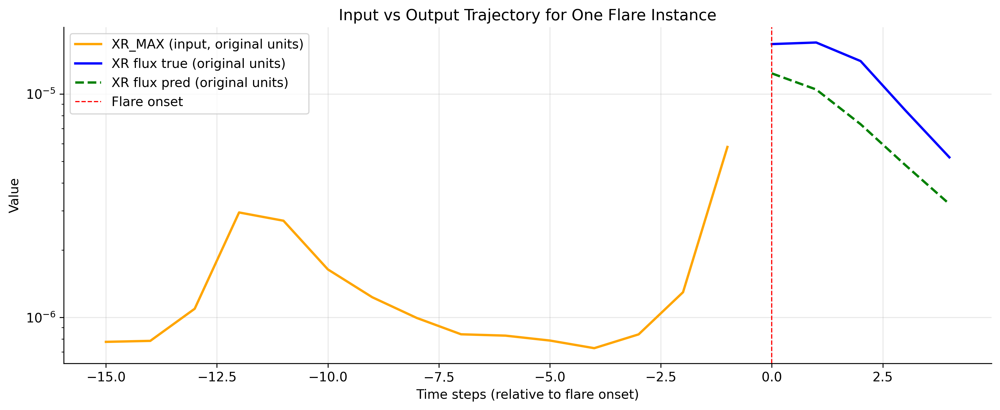

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.4166575e-05, 1.3081242e-05, 1.0437588e-05, 8.0159098e-06,
       6.3064322e-06], dtype=float32), 3) | (array([1.7130e-05, 1.7920e-05, 1.1190e-05, 7.7502e-06, 5.1628e-06]), 3)


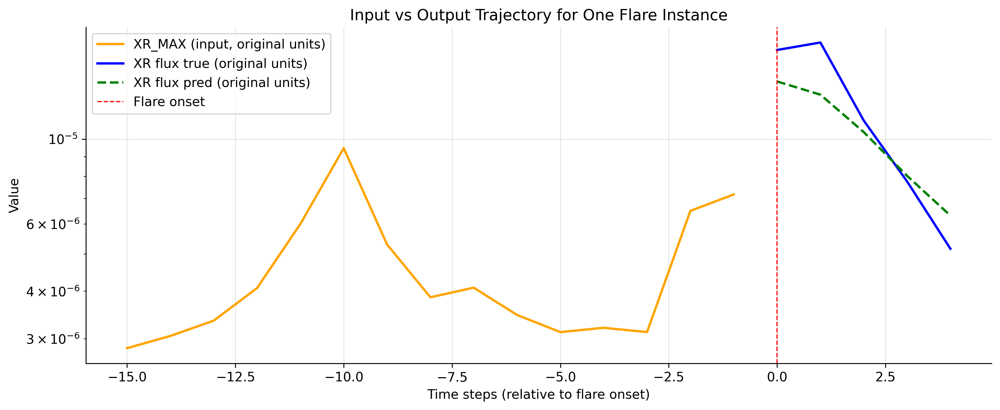

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.1374379e-05, 9.9122035e-06, 7.5439339e-06, 5.5490377e-06,
       4.1795829e-06], dtype=float32), 3) | (array([1.8428e-05, 1.7501e-05, 8.3760e-06, 5.3330e-06, 7.4673e-06]), 3)


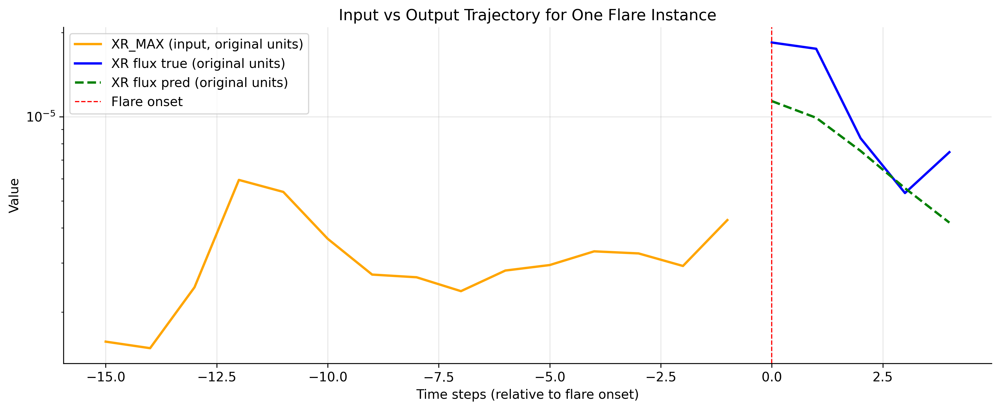

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([9.1510701e-06, 7.1973568e-06, 4.7964695e-06, 2.9822354e-06,
       1.8203268e-06], dtype=float32), 3) | (array([1.0289e-05, 1.1253e-05, 7.9606e-06, 3.8705e-06, 4.7563e-06]), 3)


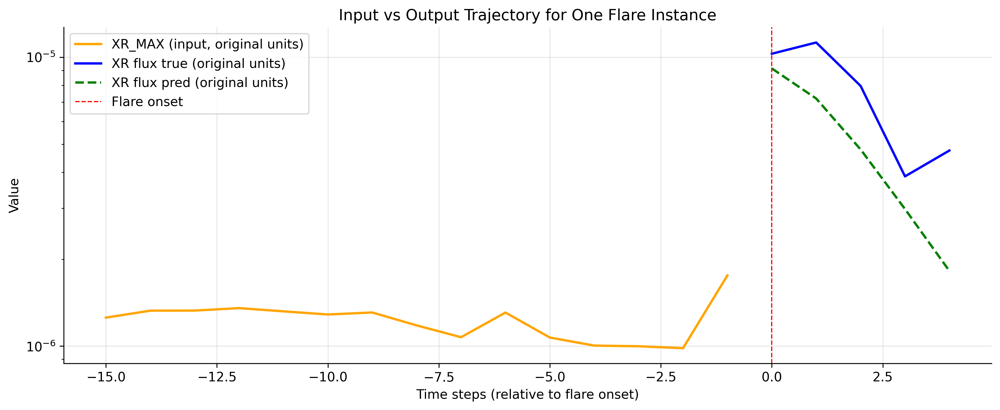

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.1737380e-06, 6.1047640e-06, 3.8336025e-06, 2.1710784e-06,
       1.1265387e-06], dtype=float32), 3) | (array([1.3006e-06, 1.4725e-05, 2.4539e-06, 1.2043e-06, 1.0623e-06]), 3)


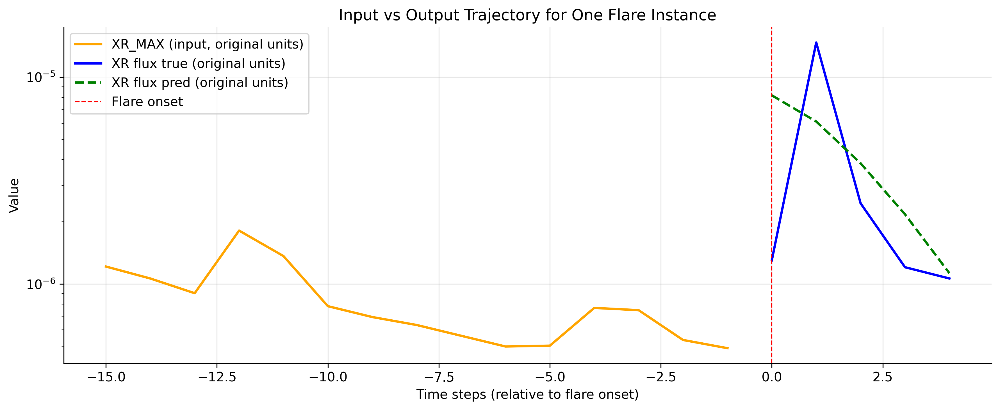

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.2329752e-06, 6.1266469e-06, 3.7660968e-06, 2.0473142e-06,
       9.7536679e-07], dtype=float32), 3) | (array([2.1798e-06, 1.0431e-05, 4.5130e-06, 1.5348e-06, 1.1033e-06]), 3)


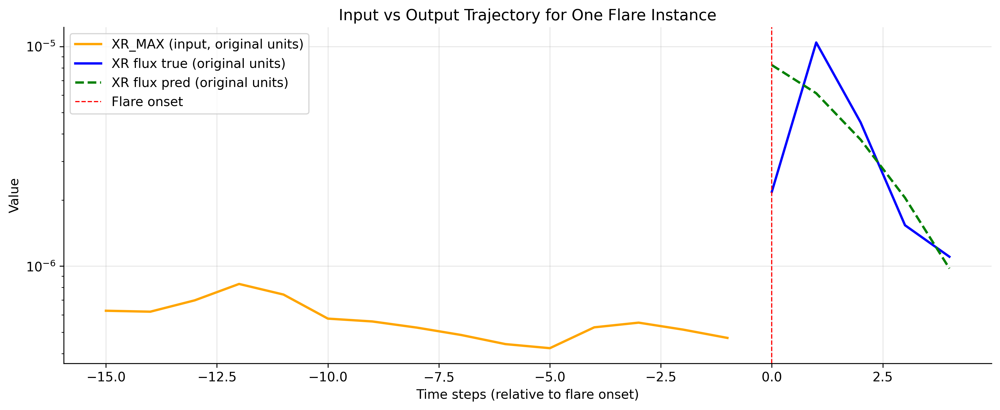

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.31987135e-05, 1.15404637e-05, 8.06608114e-06, 5.24060351e-06,
       3.45466742e-06], dtype=float32), 3) | (array([1.1775e-05, 9.7001e-06, 5.6130e-06, 3.7021e-06, 2.6131e-06]), 3)


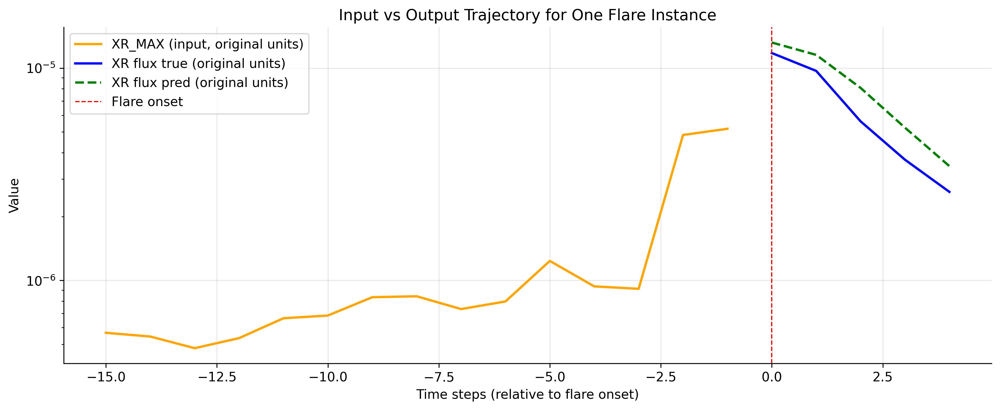

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([9.9026984e-06, 8.3592322e-06, 6.3439484e-06, 4.6927230e-06,
       3.5549197e-06], dtype=float32), 3) | (array([1.1112e-05, 1.3540e-05, 7.8816e-06, 7.0423e-06, 4.7368e-06]), 3)


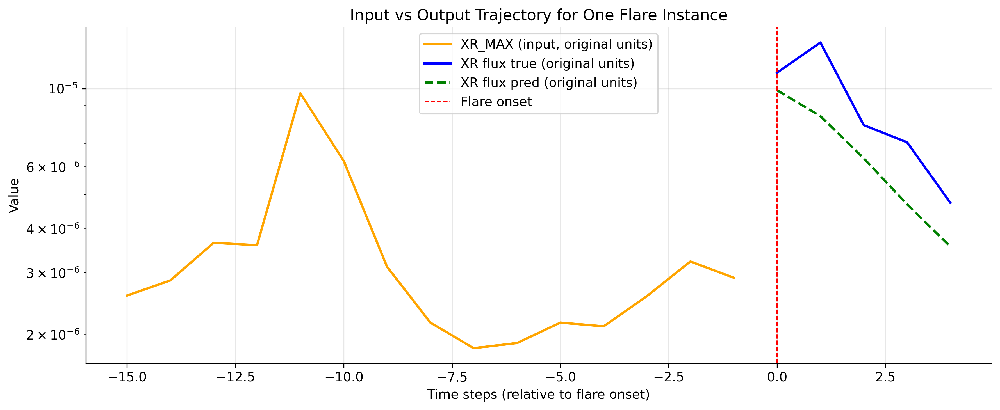

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.2209331e-05, 1.1318339e-05, 9.0521935e-06, 6.9536400e-06,
       5.4656184e-06], dtype=float32), 3) | (array([1.1742e-05, 1.0813e-05, 5.4875e-06, 3.0725e-06, 2.0206e-06]), 3)


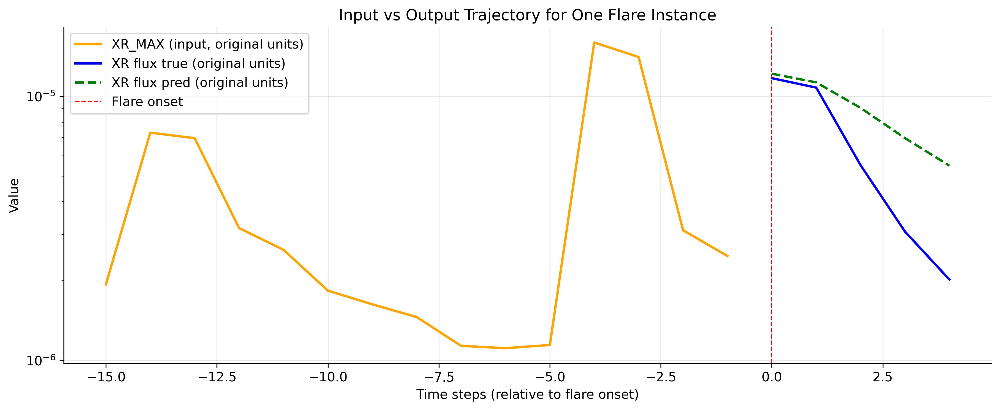

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.51399345e-05, 1.39624035e-05, 1.10279116e-05, 8.51959066e-06,
       6.87191732e-06], dtype=float32), 3) | (array([4.4185e-05, 5.4723e-05, 4.6537e-05, 2.8067e-05, 1.7220e-05]), 3)


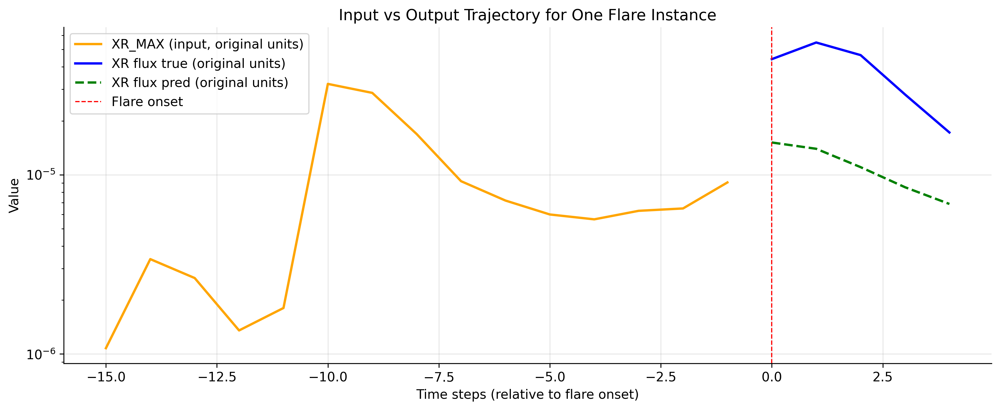

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.9872465e-06, 7.1503869e-06, 5.0026824e-06, 3.3543690e-06,
       2.2746356e-06], dtype=float32), 3) | (array([3.9784e-06, 3.8685e-05, 1.0402e-05, 5.7055e-06, 4.2676e-06]), 3)


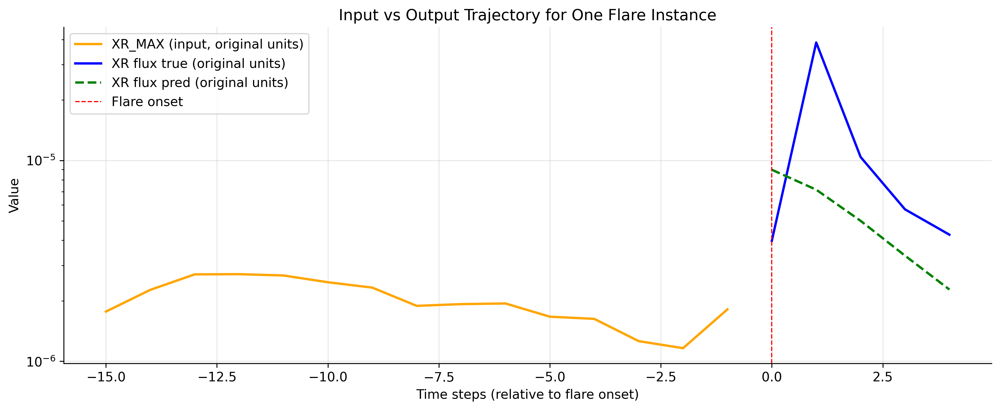

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([2.3844696e-05, 2.2125600e-05, 1.6741147e-05, 1.2819901e-05,
       1.0699046e-05], dtype=float32), 3) | (array([2.0296e-05, 1.8683e-05, 1.3356e-05, 1.0525e-05, 8.0844e-06]), 3)


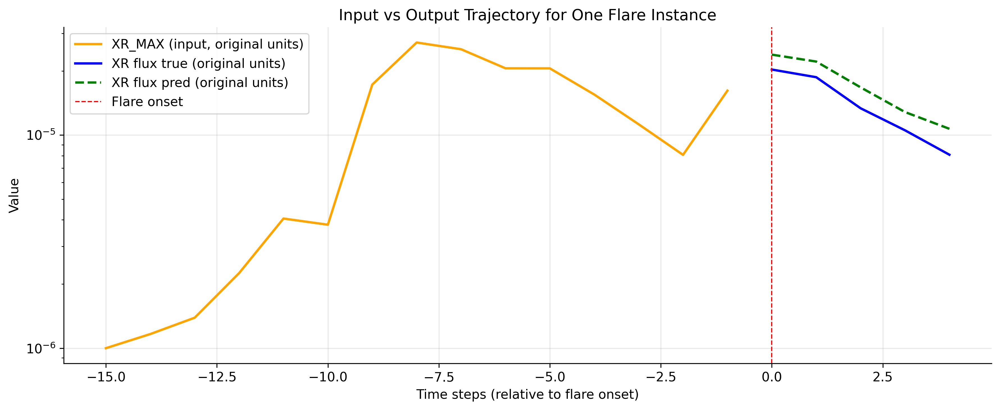

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([7.8119583e-06, 5.9899917e-06, 4.2767847e-06, 2.9825655e-06,
       2.1306532e-06], dtype=float32), 3) | (array([2.2816e-05, 1.4137e-05, 7.1787e-06, 3.8126e-06, 2.0928e-06]), 3)


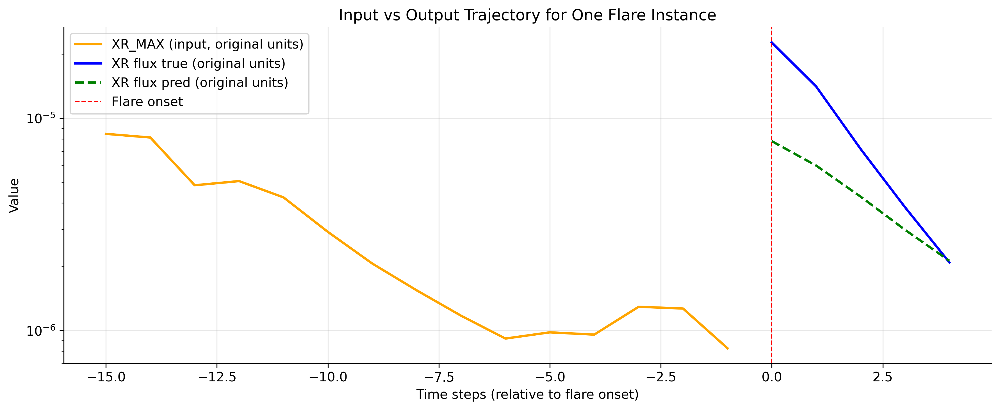

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([9.0921967e-06, 7.3280521e-06, 5.2197024e-06, 3.5797198e-06,
       2.4949741e-06], dtype=float32), 3) | (array([1.3079e-05, 1.4525e-05, 7.7005e-06, 3.5215e-06, 2.8131e-06]), 3)


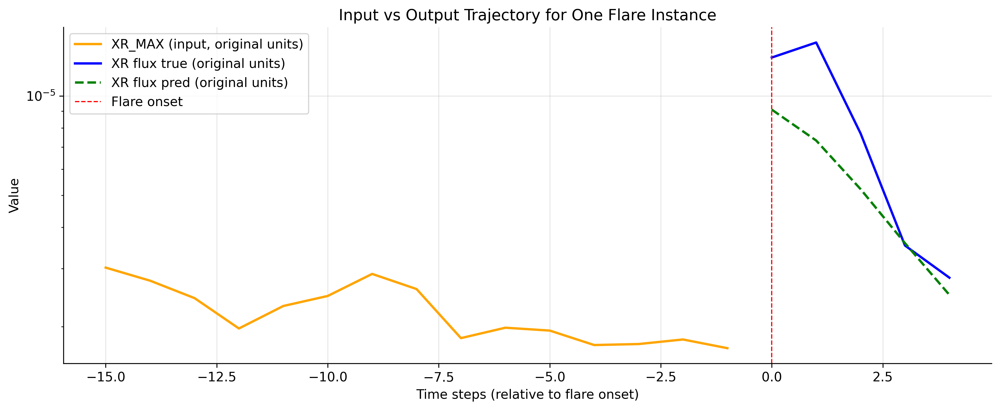

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.8605420e-06, 6.8287177e-06, 4.4395133e-06, 2.6594203e-06,
       1.5287895e-06], dtype=float32), 3) | (array([1.0558e-05, 1.1557e-05, 7.1313e-06, 3.8625e-06, 2.3010e-06]), 3)


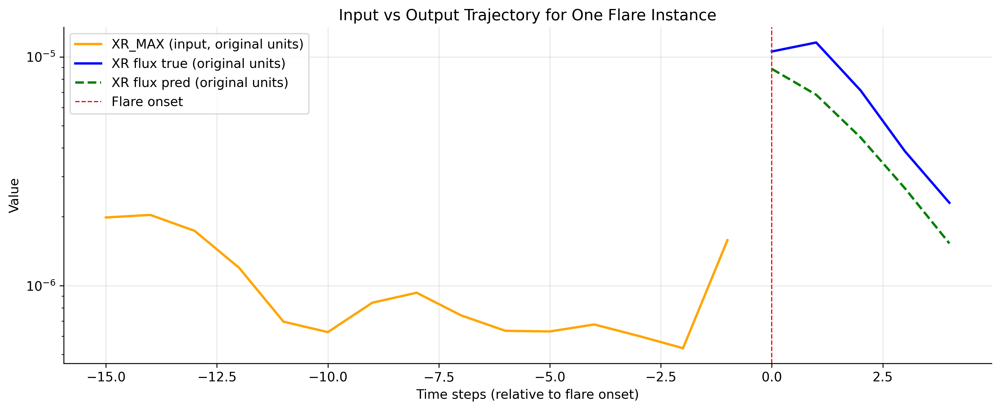

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.9807727e-06, 7.1020722e-06, 4.8466113e-06, 3.1251600e-06,
       2.0093055e-06], dtype=float32), 3) | (array([1.7201e-06, 1.0383e-05, 3.3364e-06, 2.4754e-06, 1.8761e-06]), 3)


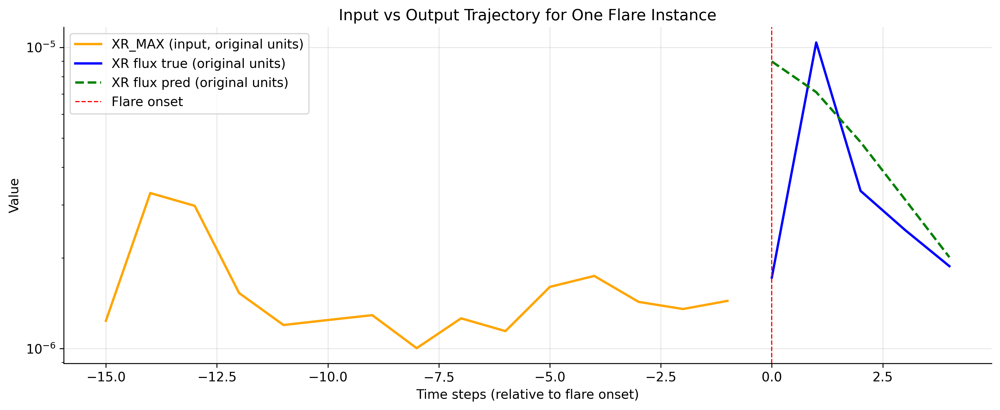

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([9.1982674e-06, 7.6040164e-06, 5.7298821e-06, 4.2494426e-06,
       3.2478094e-06], dtype=float32), 3) | (array([2.1659e-06, 3.1756e-05, 1.4732e-05, 5.6636e-06, 3.5006e-06]), 3)


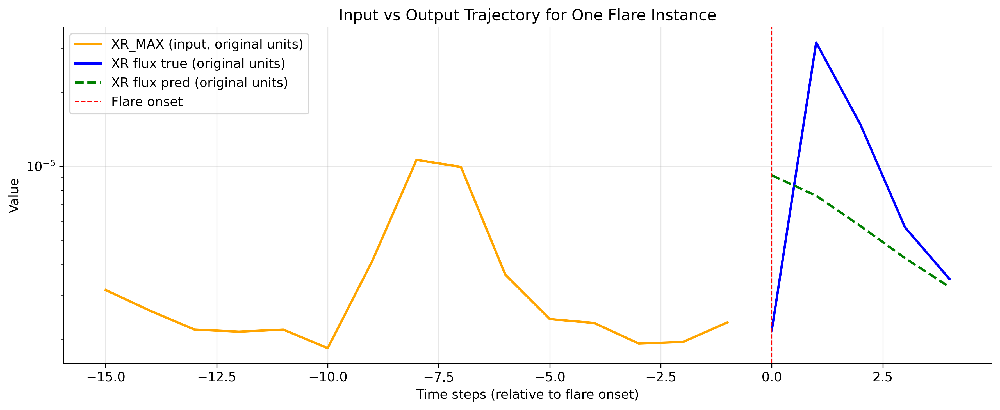

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([3.16576625e-05, 3.06502370e-05, 2.20080765e-05, 1.52232215e-05,
       1.14009035e-05], dtype=float32), 3) | (array([1.9767e-05, 1.9831e-05, 1.8494e-05, 1.1737e-05, 7.4237e-06]), 3)


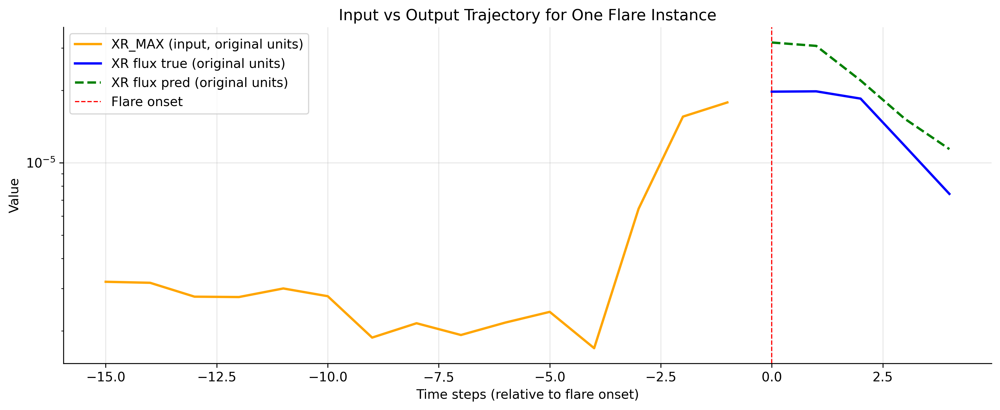

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([9.6303211e-06, 7.6527185e-06, 5.1040797e-06, 3.1668542e-06,
       1.9271324e-06], dtype=float32), 3) | (array([1.3973e-05, 1.3688e-05, 7.0110e-06, 4.5997e-06, 1.7880e-06]), 3)


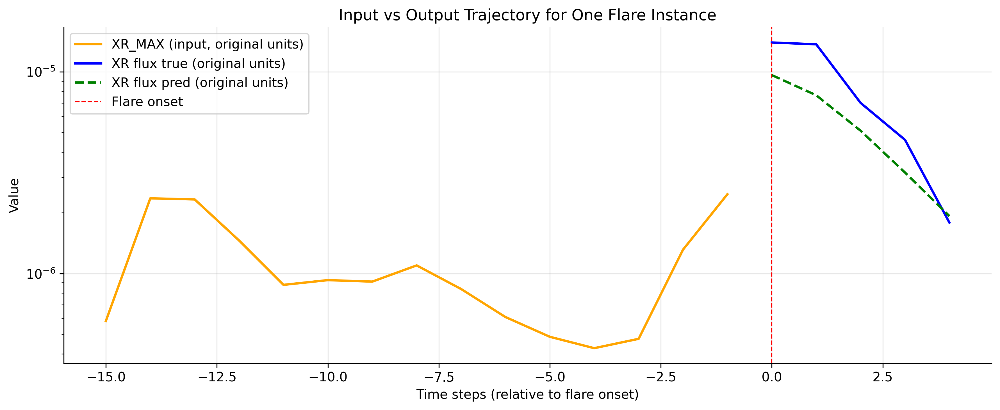

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([9.3205699e-06, 7.5181611e-06, 5.2772511e-06, 3.5445887e-06,
       2.4099297e-06], dtype=float32), 3) | (array([3.5655e-05, 2.2193e-05, 7.8468e-06, 5.1259e-06, 4.3605e-06]), 3)


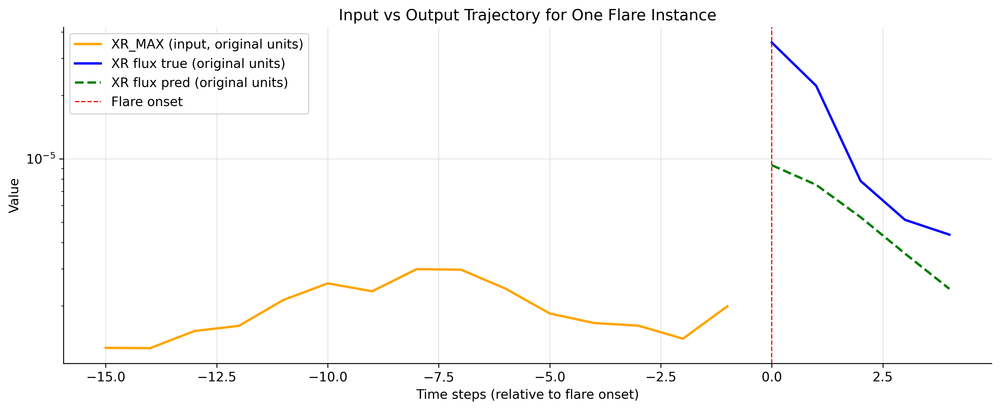

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.9809846e-06, 7.2821313e-06, 5.3442045e-06, 3.8274688e-06,
       2.8099773e-06], dtype=float32), 3) | (array([3.4532e-05, 6.9252e-05, 5.4383e-05, 4.1791e-05, 2.7433e-05]), 3)


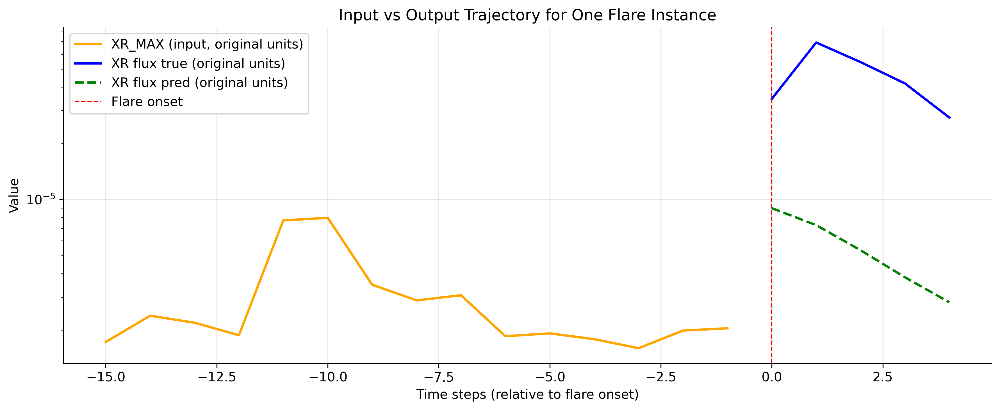

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.5143065e-06, 6.4618430e-06, 4.0804903e-06, 2.3257003e-06,
       1.2226333e-06], dtype=float32), 3) | (array([1.3055e-05, 1.3524e-05, 1.4536e-06, 9.1843e-07, 9.8950e-07]), 3)


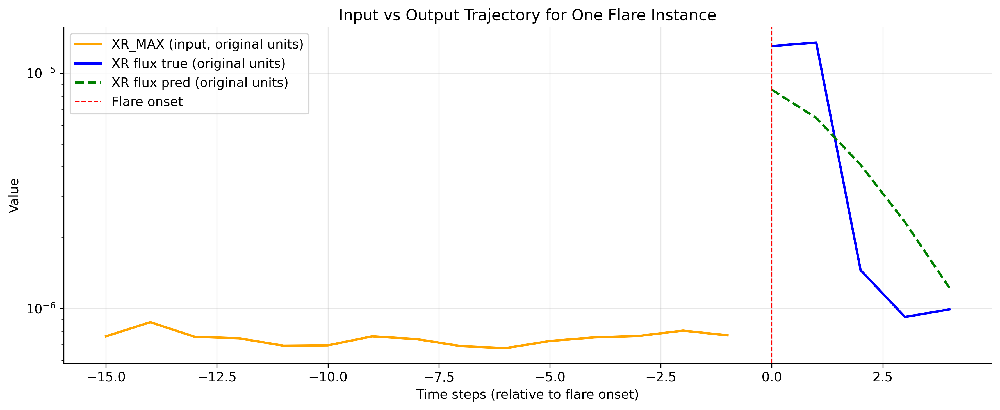

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([3.4710698e-05, 3.1819152e-05, 2.3440665e-05, 1.7228571e-05,
       1.3543918e-05], dtype=float32), 3) | (array([6.9668e-05, 7.1635e-05, 4.3837e-05, 1.1140e-05, 5.1391e-06]), 3)


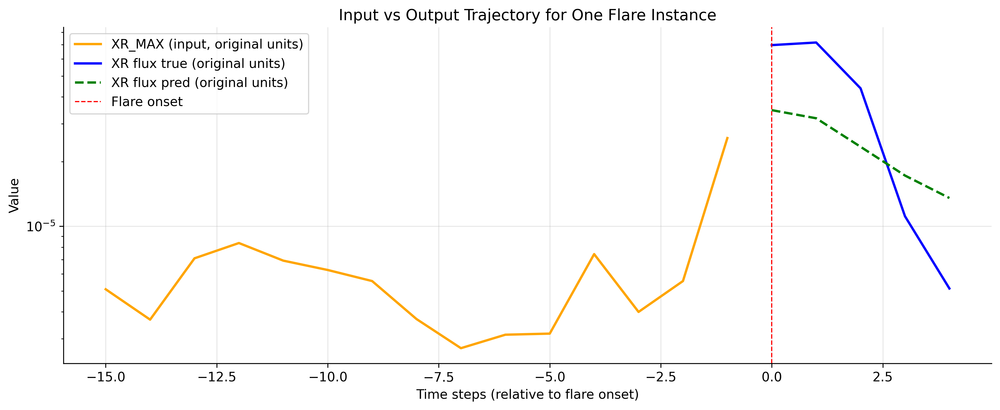

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.4610865e-06, 6.4091150e-06, 4.0349491e-06, 2.2874979e-06,
       1.1901533e-06], dtype=float32), 3) | (array([1.0300e-06, 1.2727e-05, 2.3184e-06, 7.5958e-07, 9.8758e-07]), 3)


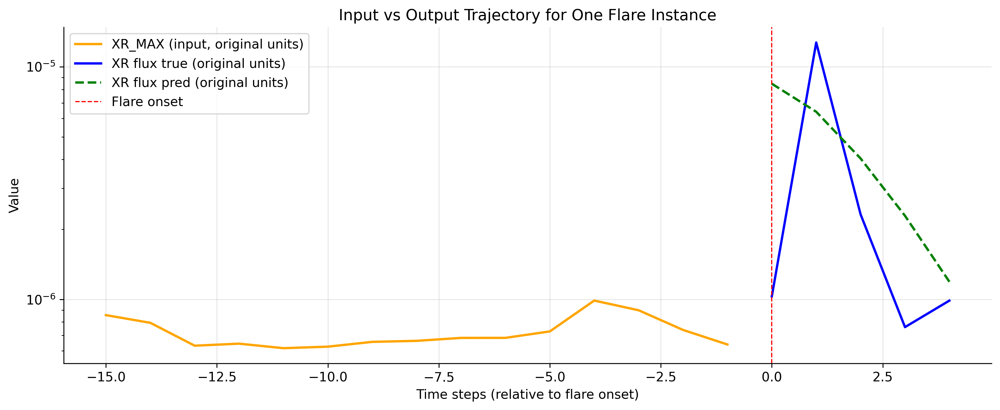

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([9.6901558e-06, 7.9710408e-06, 5.6259069e-06, 3.7783414e-06,
       2.5643731e-06], dtype=float32), 3) | (array([3.5272e-05, 1.0288e-05, 3.7874e-06, 2.7526e-06, 1.7710e-06]), 3)


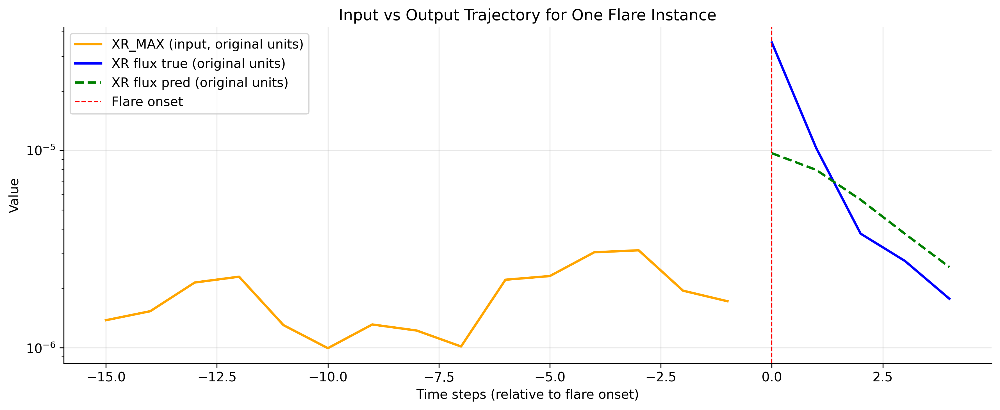

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.3838795e-06, 6.2720546e-06, 3.8433386e-06, 2.0730283e-06,
       9.7090663e-07], dtype=float32), 3) | (array([2.4522e-05, 1.3085e-05, 3.5330e-06, 7.3793e-07, 4.3557e-07]), 3)


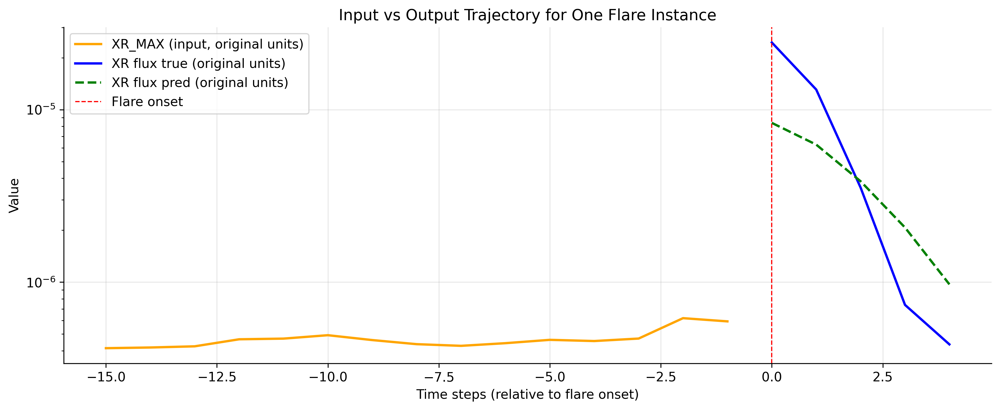

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.7902436e-06, 7.2192433e-06, 5.5577916e-06, 4.2674287e-06,
       3.3937611e-06], dtype=float32), 3) | (array([2.0501e-05, 4.2408e-05, 6.8145e-06, 2.1964e-06, 1.8119e-06]), 3)


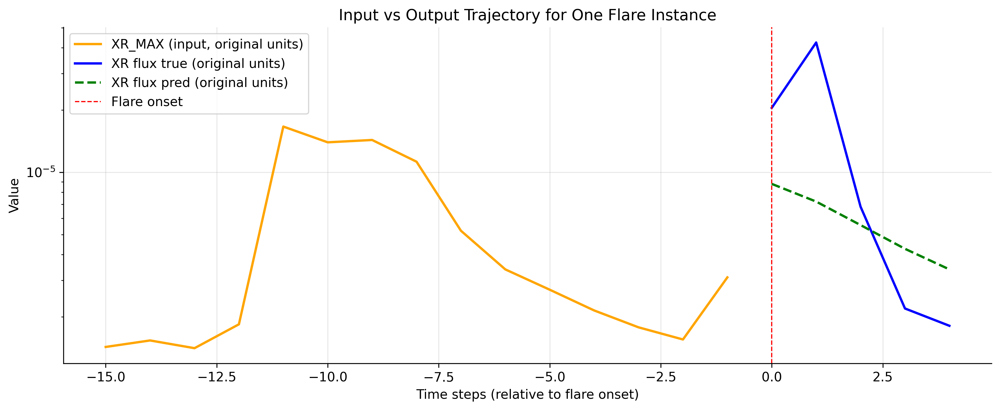

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([9.4334382e-06, 8.0000109e-06, 6.3039893e-06, 4.9099954e-06,
       3.9304932e-06], dtype=float32), 3) | (array([3.1167e-06, 1.1178e-05, 2.7655e-06, 2.3875e-06, 2.3023e-06]), 3)


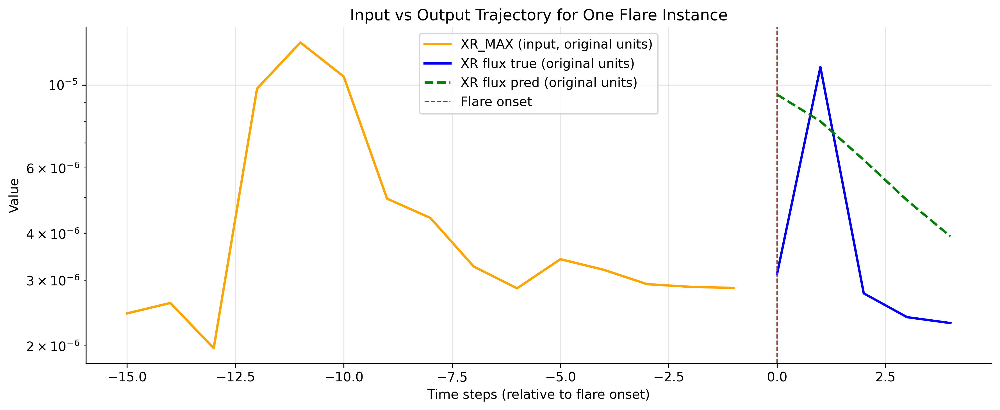

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.9245632e-06, 7.0181818e-06, 4.6928403e-06, 2.9313044e-06,
       1.8006916e-06], dtype=float32), 3) | (array([1.0001e-06, 1.2997e-05, 2.1022e-06, 2.1147e-06, 1.9816e-06]), 3)


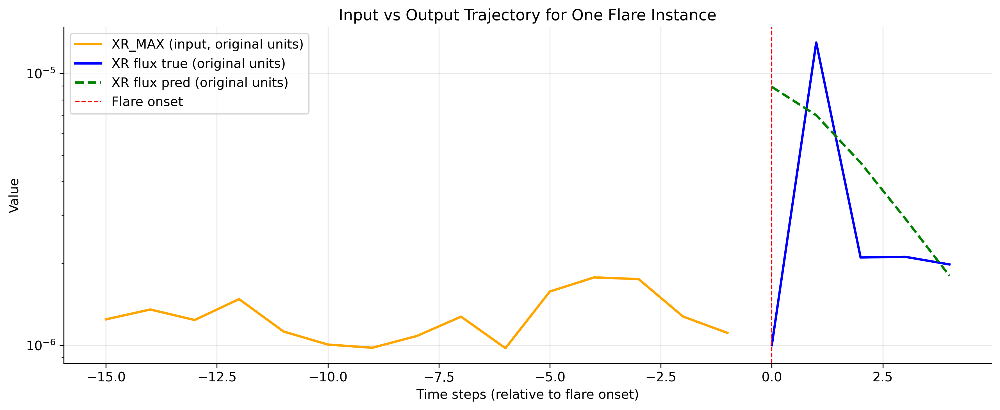

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.0671487e-05, 8.7188337e-06, 5.8246505e-06, 3.5989437e-06,
       2.1886719e-06], dtype=float32), 3) | (array([1.7873e-05, 2.0018e-05, 1.6638e-05, 1.0567e-05, 6.1130e-06]), 3)


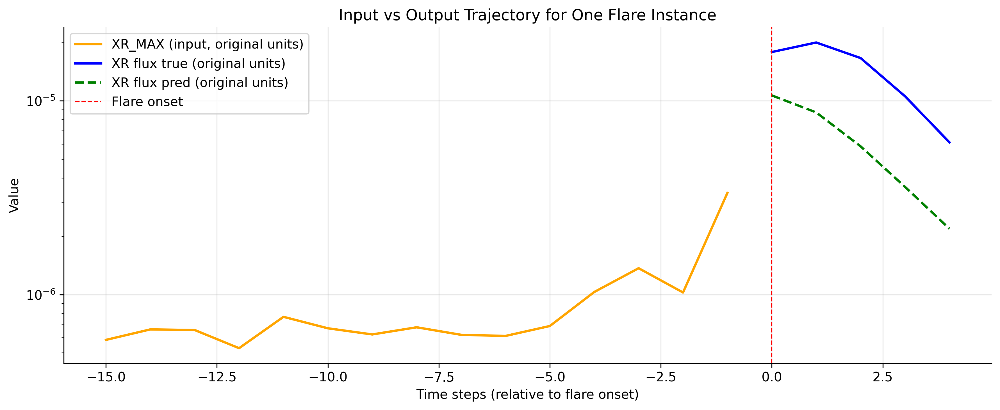

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.0260470e-05, 8.4844860e-06, 6.0589614e-06, 4.1427093e-06,
       2.8772029e-06], dtype=float32), 3) | (array([1.1972e-05, 6.1506e-06, 2.8587e-06, 1.8487e-06, 1.2472e-06]), 3)


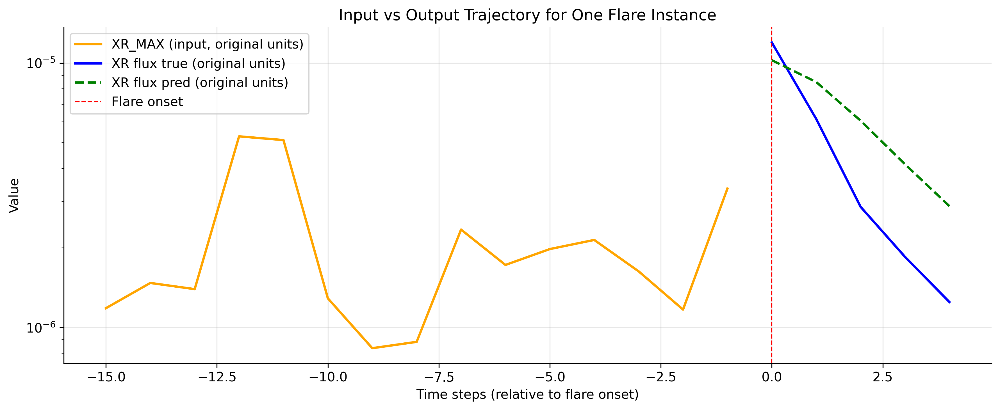

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([9.0631120e-06, 7.1100749e-06, 4.7320682e-06, 2.9364949e-06,
       1.7863771e-06], dtype=float32), 3) | (array([1.1119e-05, 8.2135e-06, 4.4503e-06, 2.4440e-06, 2.1905e-06]), 3)


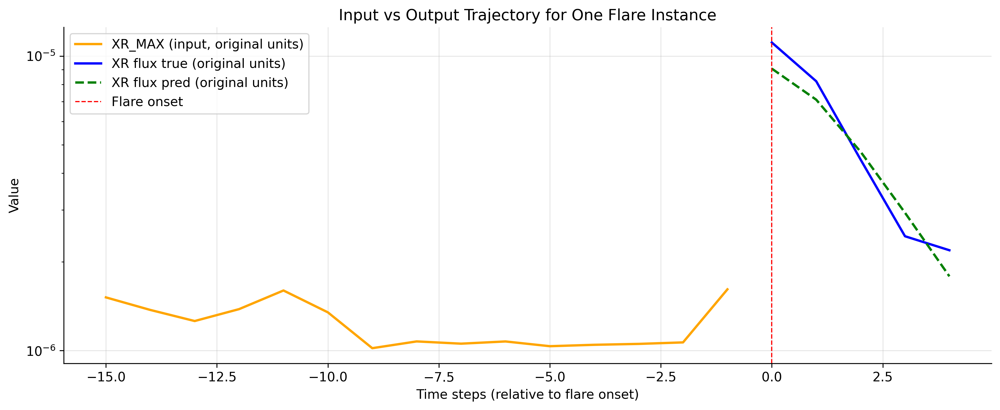

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.1315853e-05, 9.3898916e-06, 6.4561036e-06, 4.1654821e-06,
       2.6979010e-06], dtype=float32), 3) | (array([1.2373e-05, 1.1328e-05, 5.7705e-06, 2.7932e-06, 1.8222e-06]), 3)


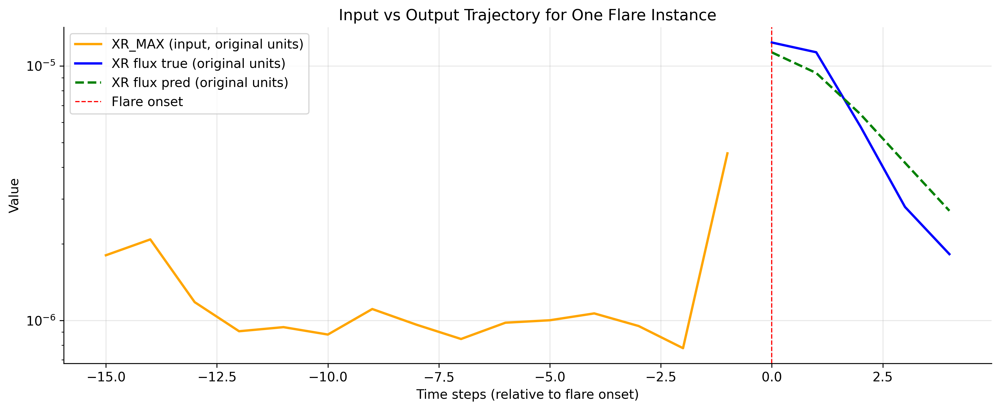

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([9.4844290e-06, 8.0484169e-06, 6.3357365e-06, 4.9130322e-06,
       3.9071319e-06], dtype=float32), 3) | (array([5.4756e-06, 1.2947e-05, 3.8101e-06, 3.4245e-06, 2.9425e-06]), 3)


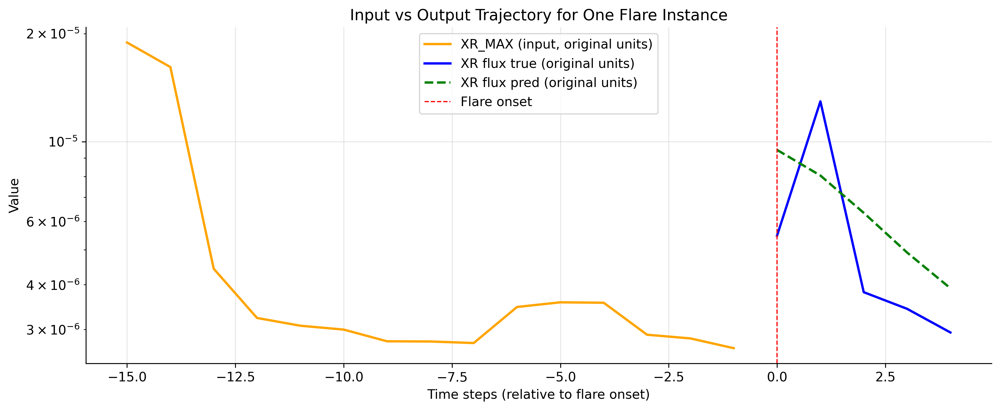

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.3357754e-06, 6.1913911e-06, 3.7538114e-06, 1.9860006e-06,
       8.8891738e-07], dtype=float32), 3) | (array([1.1712e-05, 1.3832e-05, 8.2771e-06, 4.2415e-06, 1.2668e-06]), 3)


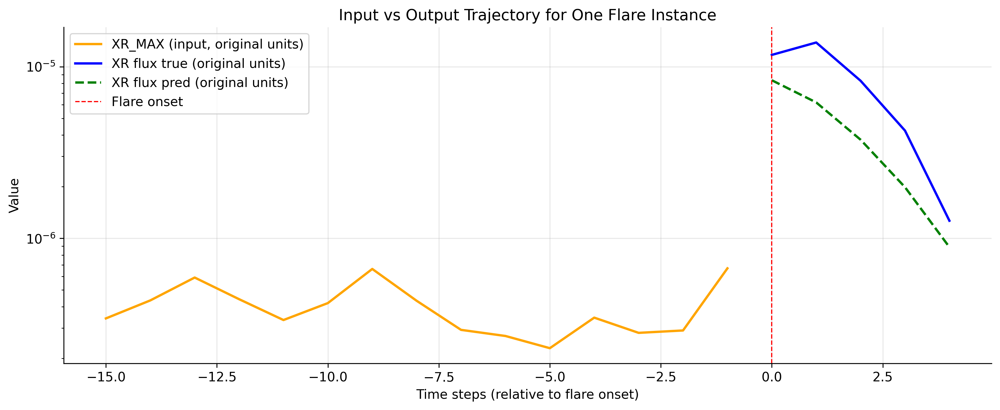

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([9.0194444e-06, 7.2742500e-06, 5.2661703e-06, 3.7020191e-06,
       2.6594348e-06], dtype=float32), 3) | (array([2.0874e-05, 2.3324e-05, 1.3619e-05, 9.0120e-06, 5.8988e-06]), 3)


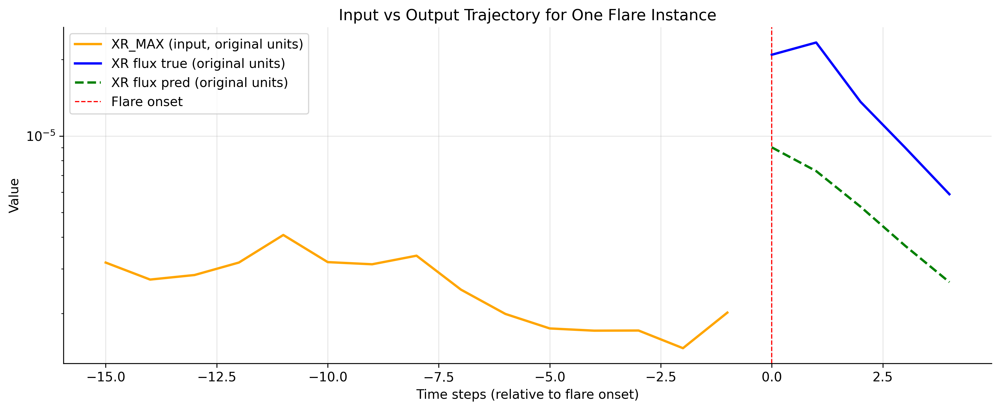

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.3379595e-05, 1.2203989e-05, 9.3931667e-06, 6.8878171e-06,
       5.1730985e-06], dtype=float32), 3) | (array([2.3373e-05, 1.8148e-05, 5.6869e-06, 2.8548e-06, 2.4214e-06]), 3)


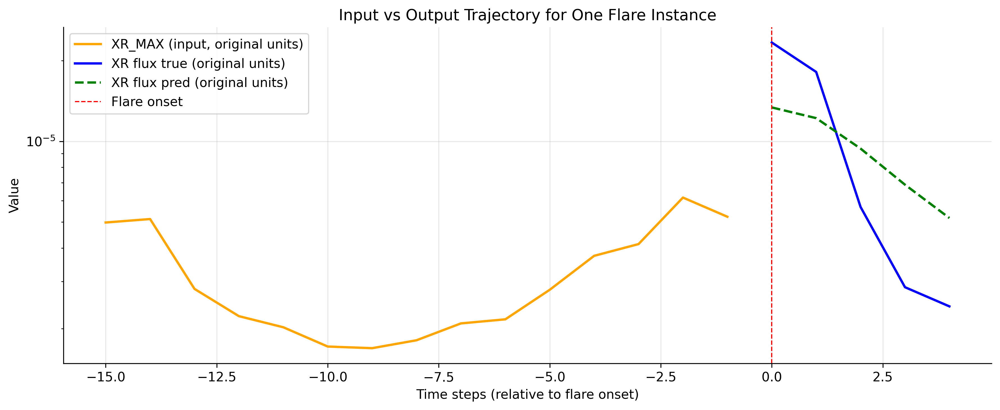

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([3.0871466e-05, 2.8677414e-05, 2.0549340e-05, 1.4383108e-05,
       1.0854541e-05], dtype=float32), 3) | (array([3.4872e-05, 3.4921e-05, 2.8387e-05, 2.1276e-05, 5.9390e-05]), 3)


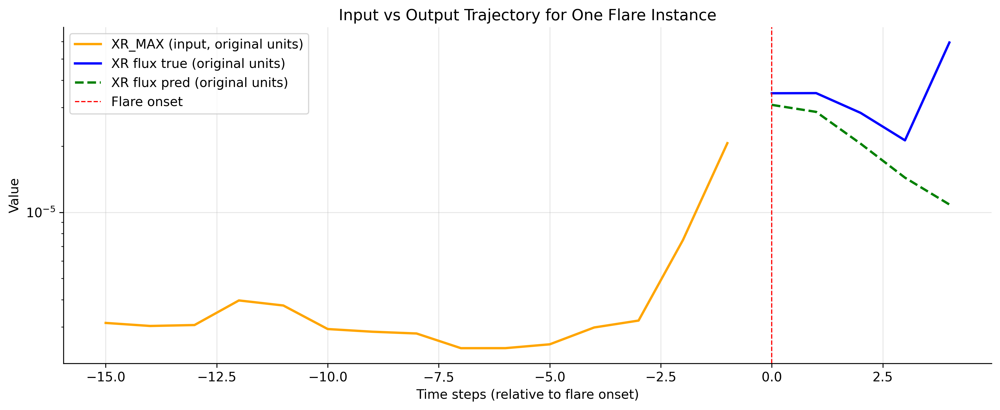

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.7152484e-06, 6.7160386e-06, 4.3347618e-06, 2.5624977e-06,
       1.4408758e-06], dtype=float32), 3) | (array([2.0564e-05, 1.7901e-05, 8.4045e-07, 5.3507e-07, 6.1870e-07]), 3)


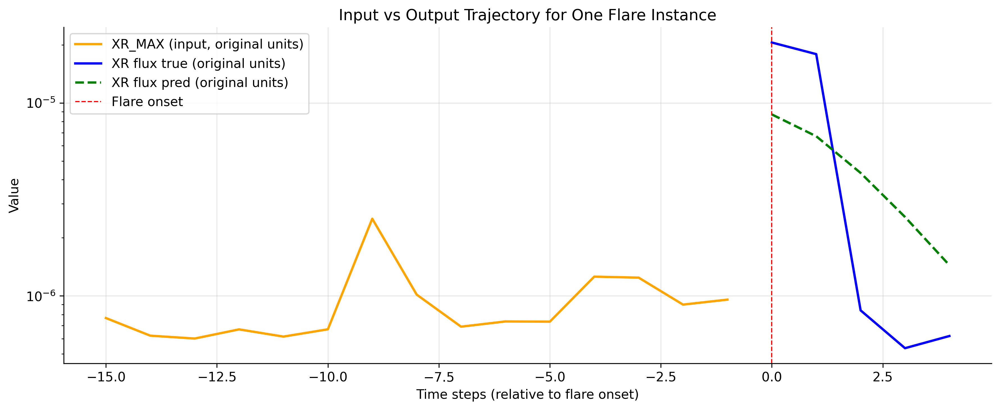

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([7.7699833e-06, 5.9533777e-06, 4.2829029e-06, 3.0216265e-06,
       2.1892504e-06], dtype=float32), 3) | (array([5.1933e-05, 1.3812e-05, 1.0899e-06, 6.5809e-07, 1.3456e-06]), 3)


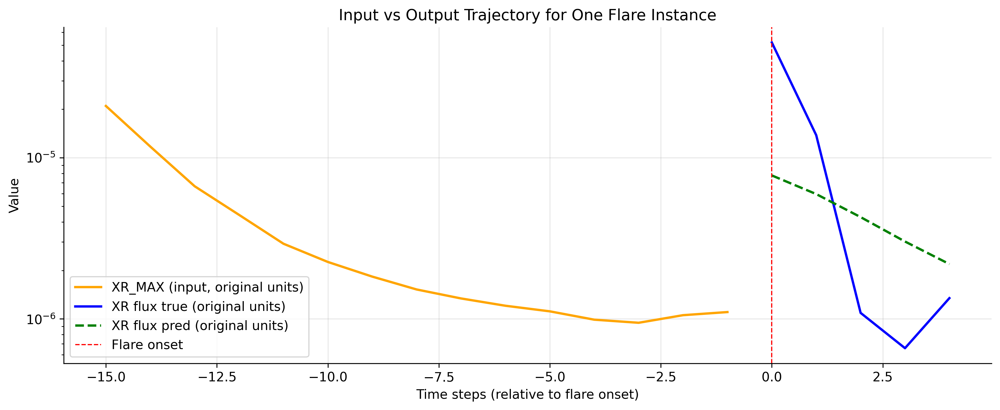

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.0980126e-05, 9.6769108e-06, 7.6940678e-06, 5.9788013e-06,
       4.7562062e-06], dtype=float32), 3) | (array([1.3056e-05, 8.2049e-06, 5.3935e-06, 4.3329e-06, 5.2541e-06]), 3)


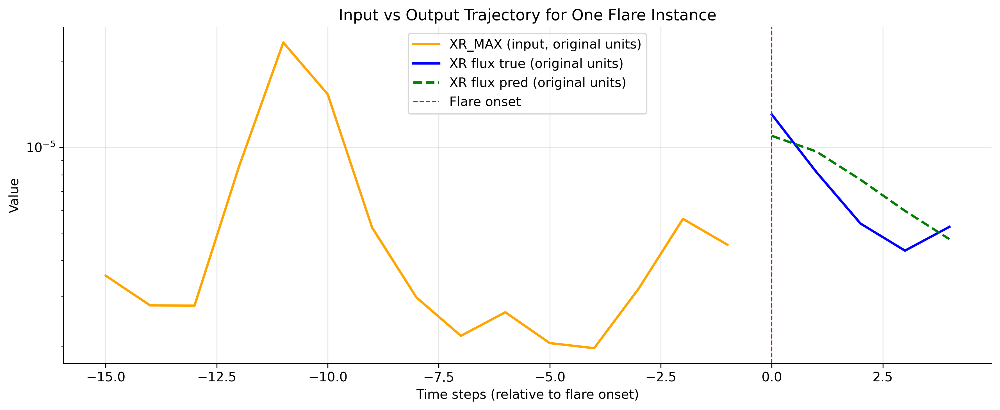

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.20877385e-05, 1.11044646e-05, 9.09414484e-06, 7.23851645e-06,
       5.88354987e-06], dtype=float32), 3) | (array([1.8882e-05, 1.6777e-05, 6.7404e-06, 3.5640e-06, 5.4432e-06]), 3)


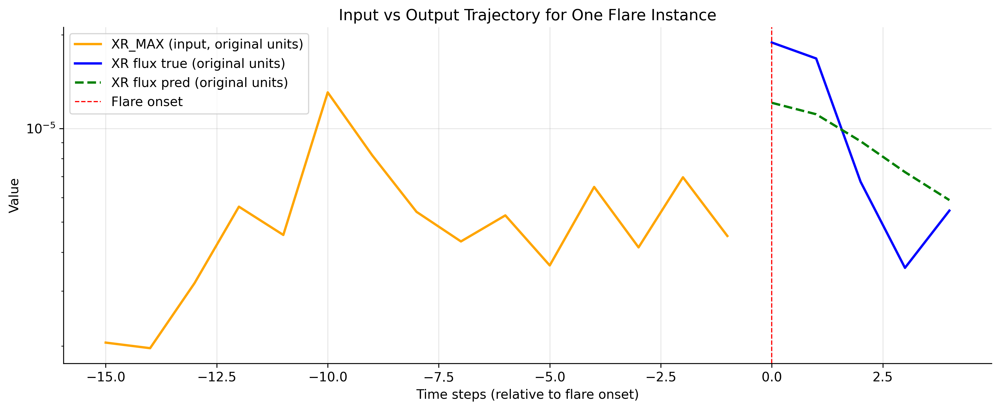

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.4658534e-05, 1.3024706e-05, 9.5803516e-06, 6.8031040e-06,
       5.0612839e-06], dtype=float32), 3) | (array([2.3375e-05, 1.5370e-05, 5.2203e-06, 2.9636e-06, 2.1740e-06]), 3)


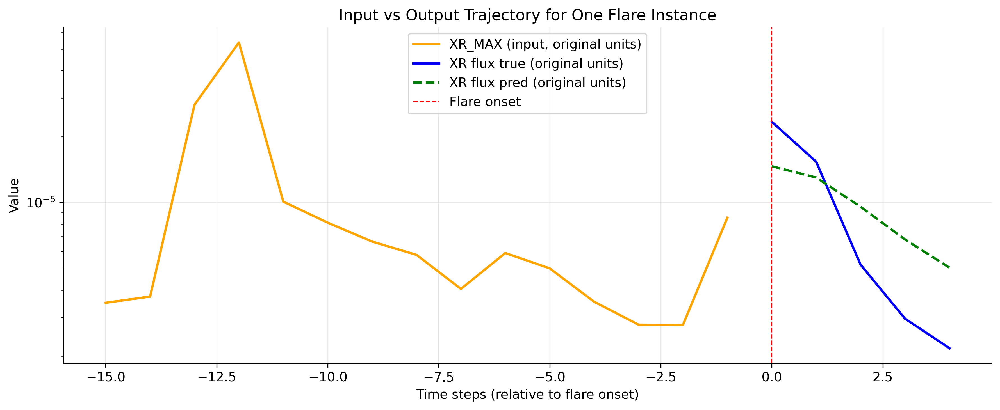

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.4503408e-06, 6.4217375e-06, 4.1053345e-06, 2.3949467e-06,
       1.3153500e-06], dtype=float32), 3) | (array([8.6931e-07, 4.9615e-05, 1.2546e-05, 3.6833e-06, 1.8406e-06]), 3)


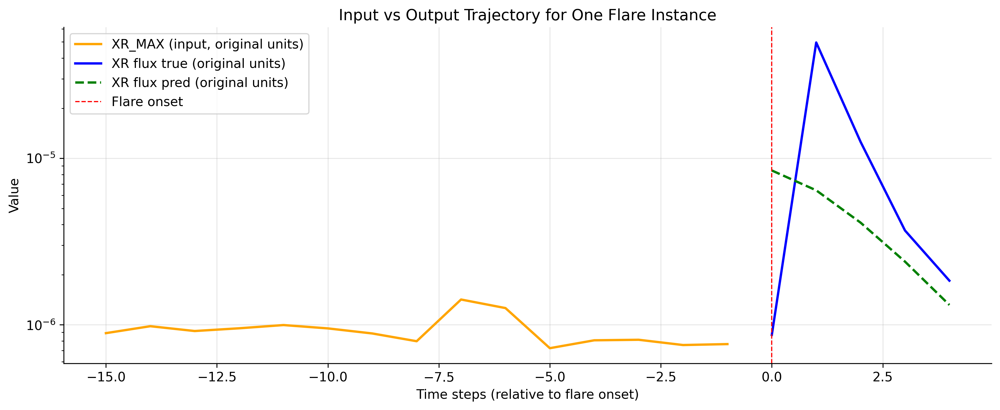

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.7818726e-05, 1.5885020e-05, 1.0972611e-05, 7.0872570e-06,
       4.7748454e-06], dtype=float32), 3) | (array([4.7054e-05, 4.5714e-05, 2.1226e-05, 1.1808e-05, 9.9112e-06]), 3)


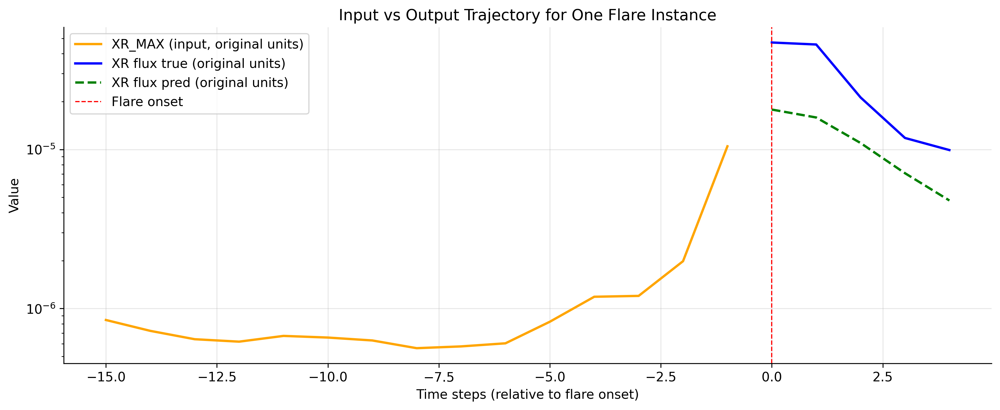

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.1483883e-05, 9.6956719e-06, 6.6763037e-06, 4.2812558e-06,
       2.7503818e-06], dtype=float32), 3) | (array([2.7993e-05, 2.0652e-05, 5.2163e-06, 2.7831e-06, 2.0246e-06]), 3)


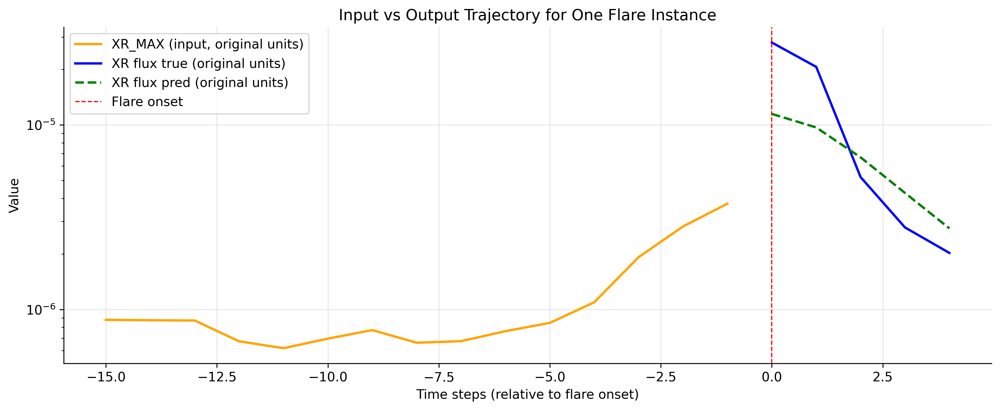

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.4491694e-06, 6.4096125e-06, 4.0686205e-06, 2.3414100e-06,
       1.2532014e-06], dtype=float32), 3) | (array([7.3341e-06, 1.1254e-05, 6.0934e-06, 1.2734e-06, 8.0119e-07]), 3)


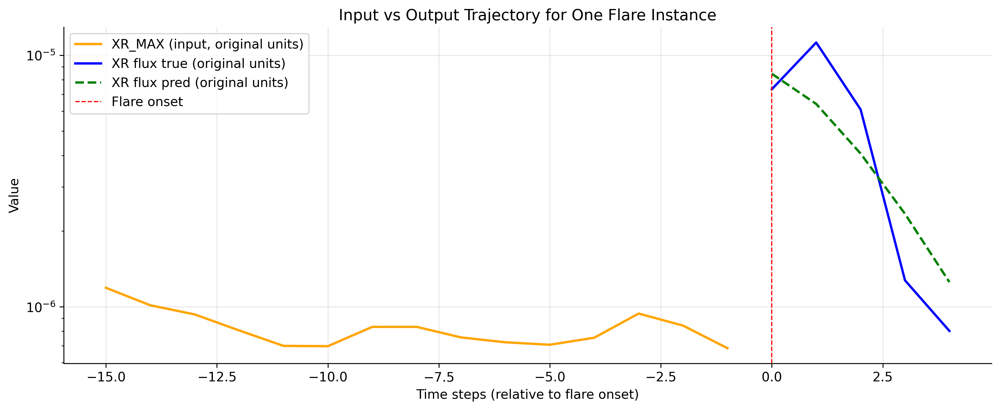

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.2779798e-06, 6.1550181e-06, 3.7434504e-06, 1.9917613e-06,
       9.0345839e-07], dtype=float32), 3) | (array([1.0036e-05, 7.2992e-06, 5.0576e-07, 3.9088e-07, 5.0929e-07]), 3)


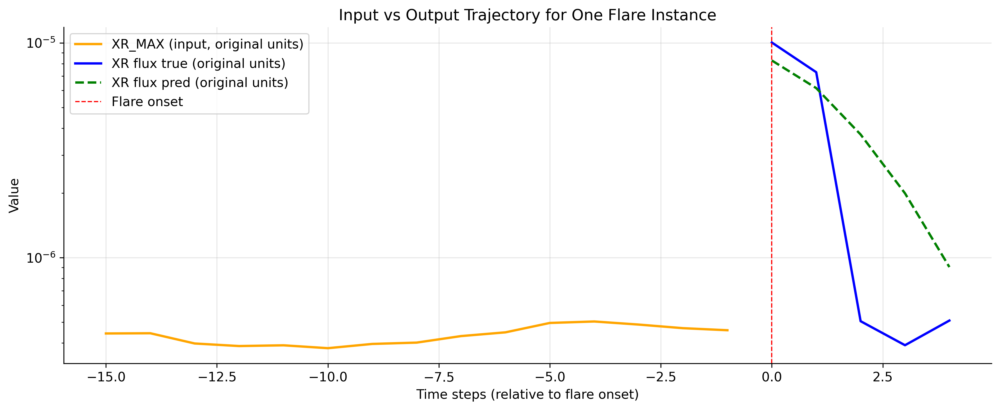

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.9205359e-06, 6.9061934e-06, 4.4577350e-06, 2.6320533e-06,
       1.4771166e-06], dtype=float32), 3) | (array([7.1282e-07, 1.3456e-05, 3.3728e-06, 1.5703e-06, 9.1369e-07]), 3)


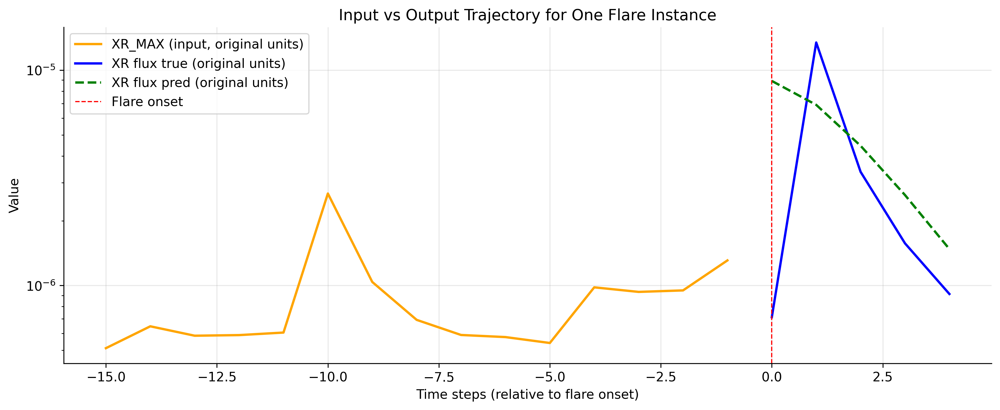

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([7.6213150e-06, 6.1205023e-06, 4.5737124e-06, 3.4787374e-06,
       2.8052834e-06], dtype=float32), 3) | (array([1.2471e-05, 1.2516e-05, 8.2380e-06, 7.4846e-06, 7.4756e-06]), 3)


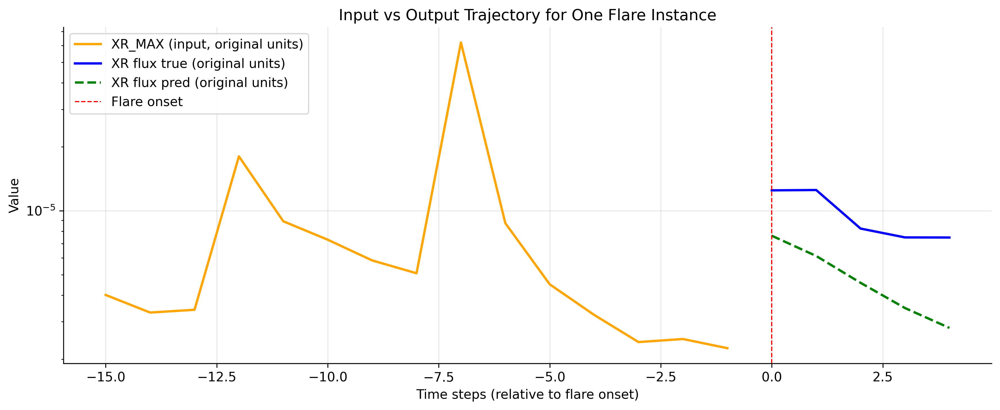

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.43083425e-05, 1.38452288e-05, 1.20900131e-05, 1.03294724e-05,
       9.01061230e-06], dtype=float32), 3) | (array([3.5984e-05, 4.4630e-05, 1.5499e-05, 7.0502e-06, 5.1556e-06]), 3)


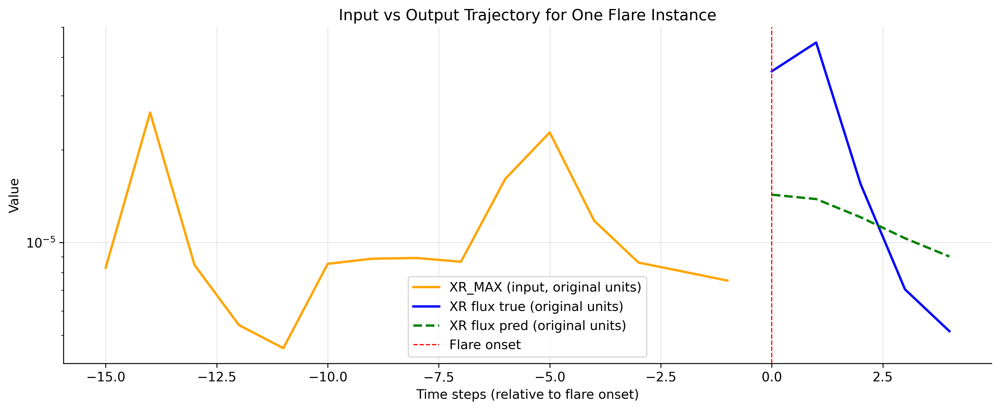

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.4001883e-05, 1.2139528e-05, 8.4896674e-06, 5.5683035e-06,
       3.7318125e-06], dtype=float32), 3) | (array([1.2027e-05, 1.1957e-05, 9.5679e-06, 8.3011e-06, 6.3419e-06]), 3)


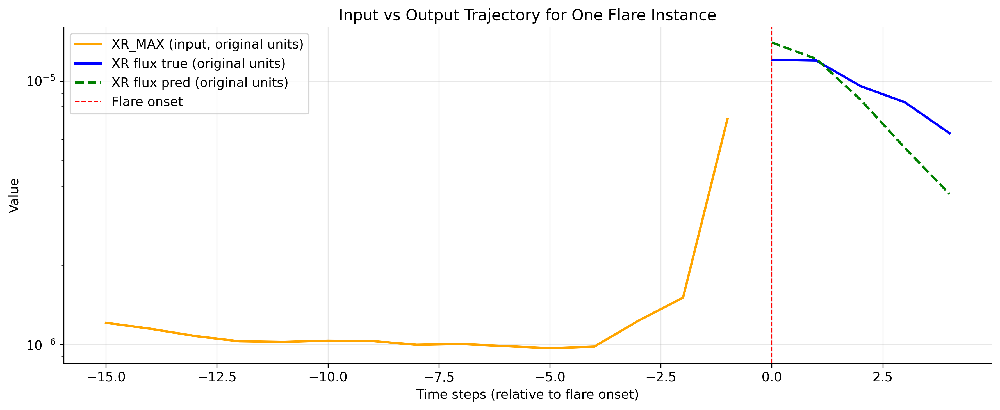

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([9.8346300e-06, 7.9968677e-06, 5.5688929e-06, 3.6779547e-06,
       2.4427015e-06], dtype=float32), 3) | (array([1.6464e-05, 1.7728e-05, 7.2218e-06, 2.6719e-06, 1.9443e-06]), 3)


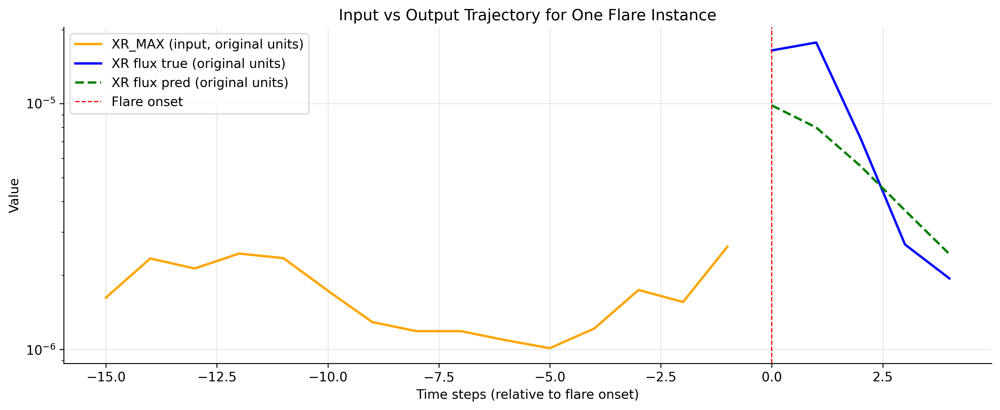

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.1338879e-05, 9.8774126e-06, 7.3451019e-06, 5.2347291e-06,
       3.8175090e-06], dtype=float32), 3) | (array([1.3350e-05, 1.4000e-05, 1.3377e-05, 1.1573e-05, 9.4718e-06]), 3)


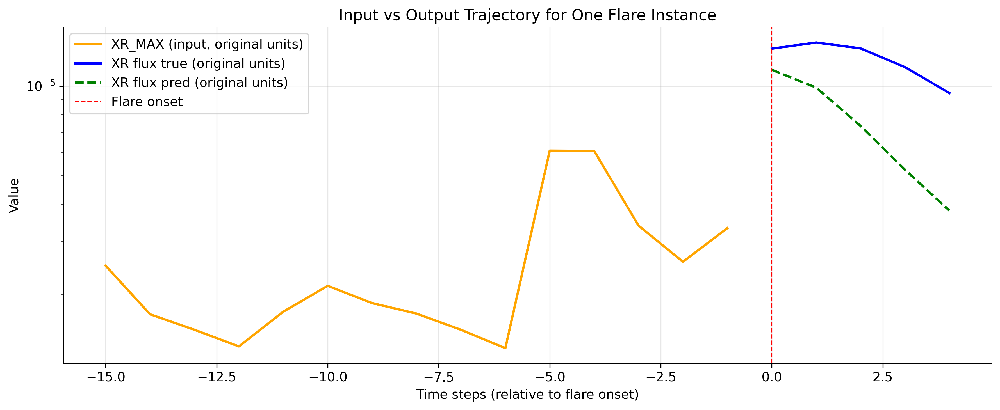

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.8837472e-05, 1.6479953e-05, 1.2342437e-05, 9.6537942e-06,
       8.4967342e-06], dtype=float32), 3) | (array([2.1492e-05, 1.8414e-05, 1.2550e-05, 1.0151e-05, 8.4321e-06]), 3)


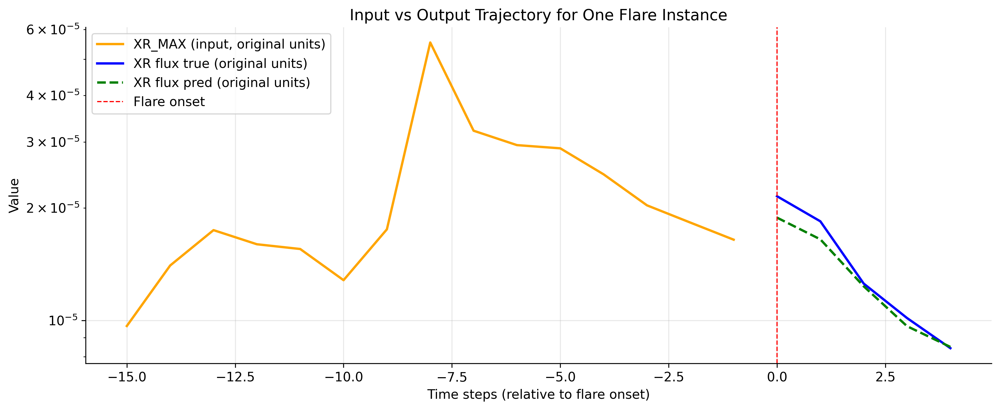

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.0327404e-05, 8.4339463e-06, 5.6629606e-06, 3.5198020e-06,
       2.1525557e-06], dtype=float32), 3) | (array([3.6864e-06, 1.0513e-05, 8.0069e-06, 3.0007e-06, 1.5949e-06]), 3)


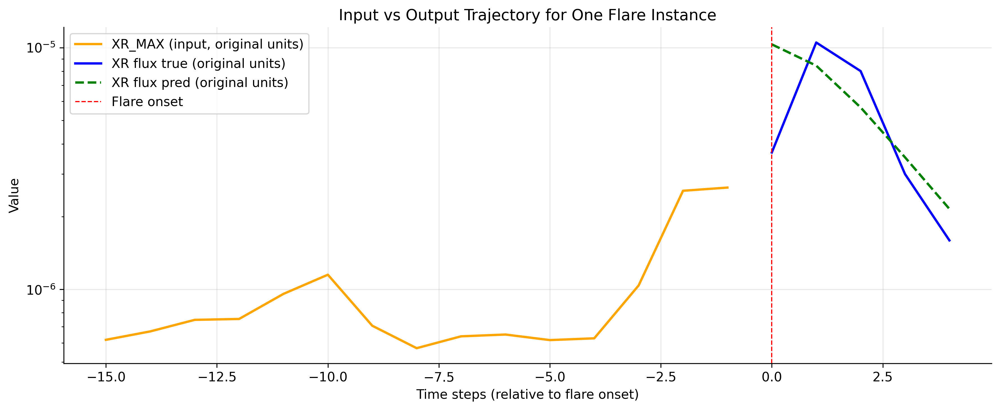

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.5382690e-06, 6.6391640e-06, 4.4987660e-06, 2.8824225e-06,
       1.8379883e-06], dtype=float32), 3) | (array([7.2379e-05, 6.7780e-05, 4.9548e-05, 2.7127e-05, 1.1541e-05]), 3)


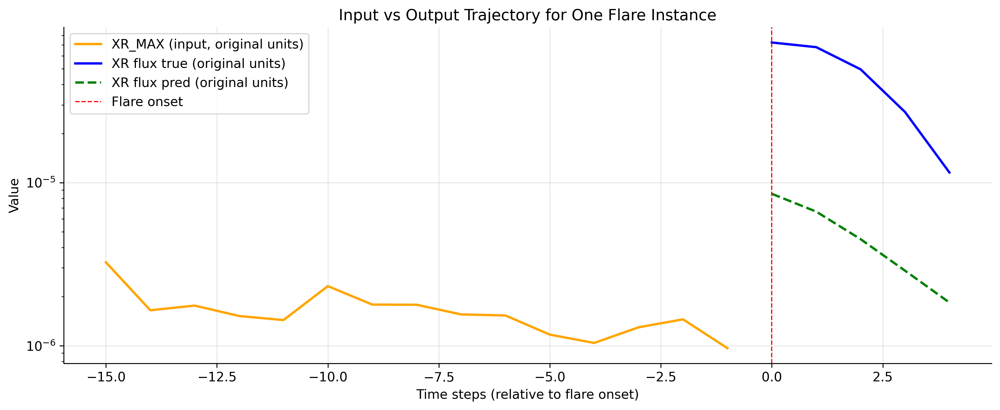

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([2.9568817e-05, 3.0422470e-05, 2.3571301e-05, 1.7588460e-05,
       1.4088221e-05], dtype=float32), 3) | (array([9.4481e-06, 1.0634e-05, 7.0260e-06, 8.6960e-06, 8.6481e-06]), 3)


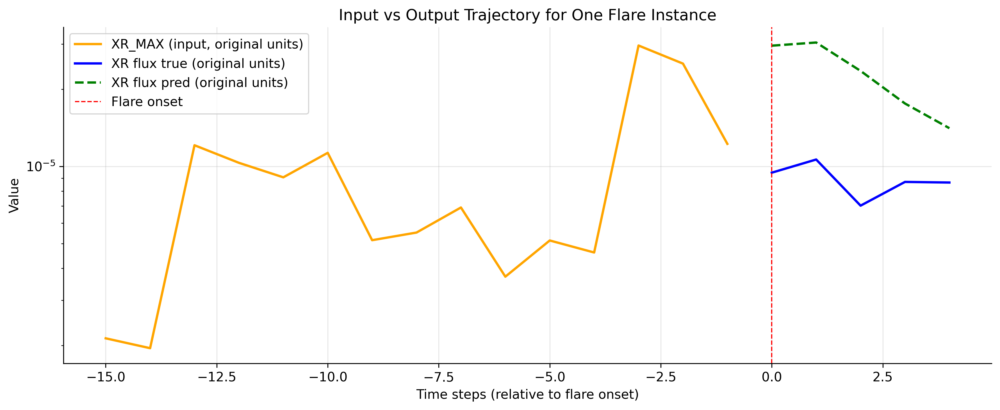

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.0157526e-05, 8.2624465e-06, 5.6464050e-06, 3.6294302e-06,
       2.3318485e-06], dtype=float32), 3) | (array([5.6350e-05, 4.7442e-05, 1.7642e-06, 1.0426e-06, 1.2216e-06]), 3)


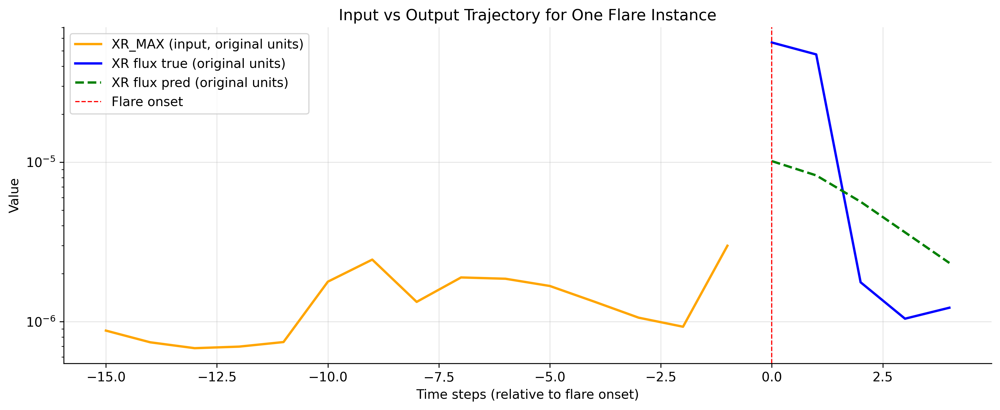

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([9.7556967e-06, 7.9441361e-06, 5.5924070e-06, 3.7574457e-06,
       2.5525742e-06], dtype=float32), 3) | (array([1.8109e-05, 7.8351e-06, 2.7036e-06, 4.6276e-06, 2.7444e-05]), 3)


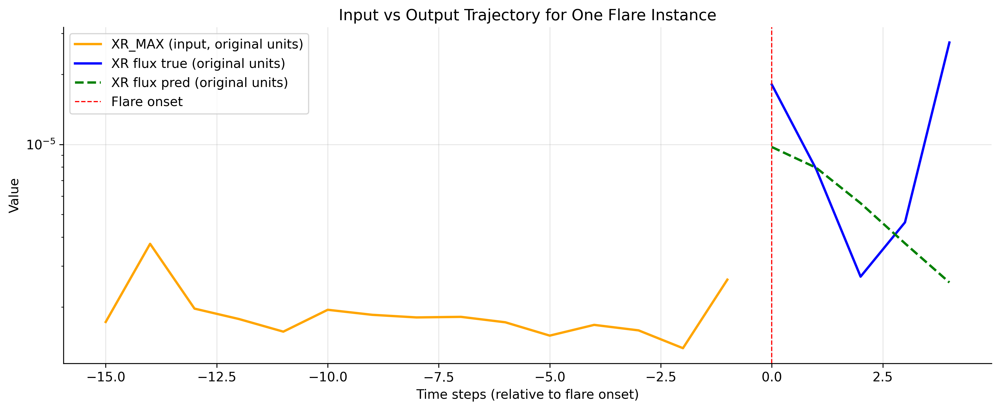

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.2258421e-06, 6.0559337e-06, 3.5865146e-06, 1.8069217e-06,
       7.0997868e-07], dtype=float32), 3) | (array([5.1472e-07, 2.0214e-05, 3.7126e-06, 6.0957e-07, 2.1754e-07]), 3)


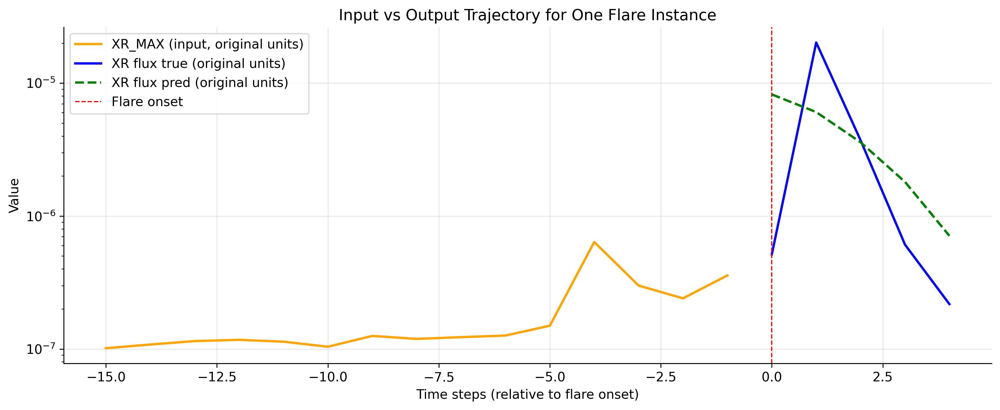

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.55236849e-05, 1.45030135e-05, 1.14638606e-05, 8.63760670e-06,
       6.66900905e-06], dtype=float32), 3) | (array([1.3787e-05, 1.4199e-05, 1.2413e-05, 1.2527e-05, 1.0944e-05]), 3)


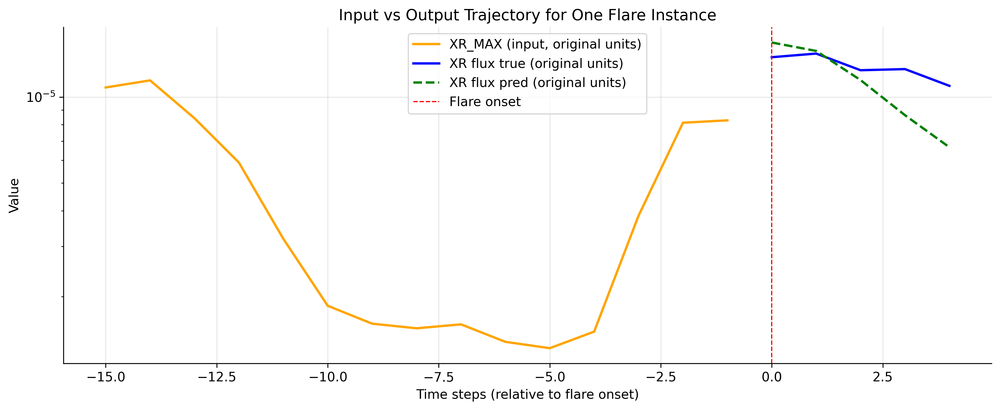

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.0458766e-05, 8.6581294e-06, 5.9543540e-06, 3.8303738e-06,
       2.4596618e-06], dtype=float32), 3) | (array([4.7196e-05, 5.2962e-05, 2.7013e-05, 1.5054e-05, 9.7808e-06]), 3)


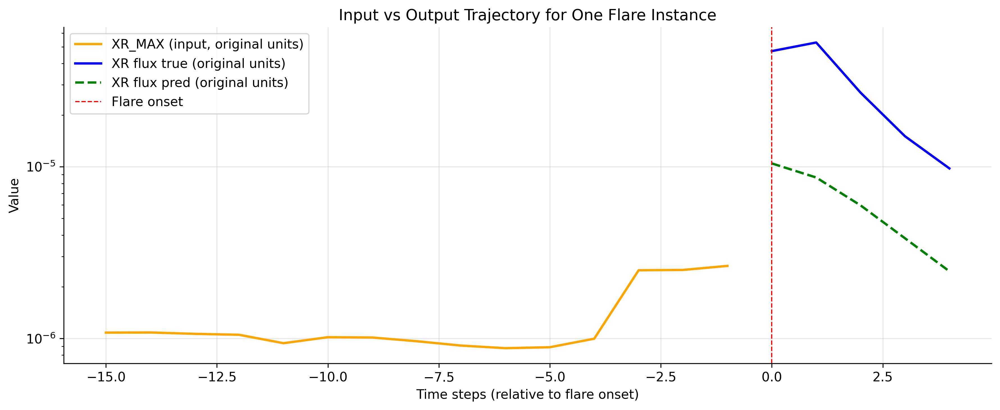

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([4.9192698e-05, 4.5906549e-05, 3.2546101e-05, 2.3132801e-05,
       1.7690885e-05], dtype=float32), 3) | (array([2.6863e-05, 2.6058e-05, 2.1725e-05, 1.6099e-05, 1.1647e-05]), 3)


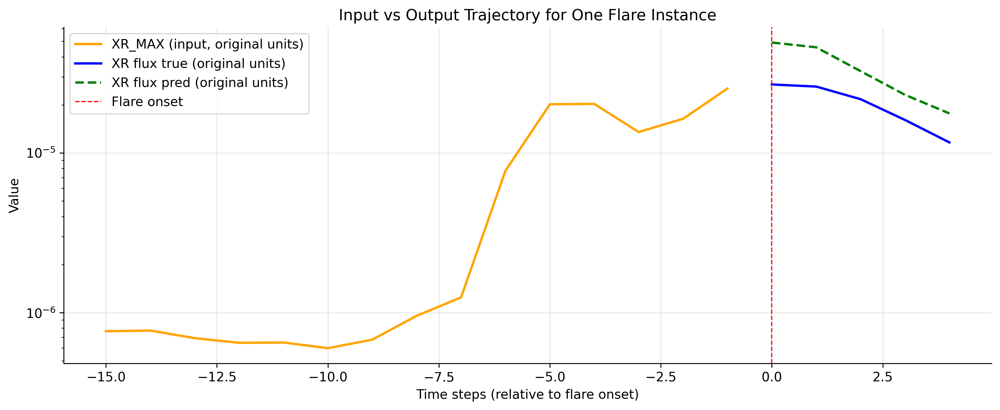

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([2.1700474e-05, 2.1378024e-05, 1.7142840e-05, 1.3109199e-05,
       1.0432930e-05], dtype=float32), 3) | (array([1.5640e-05, 1.3540e-05, 1.1876e-05, 1.2183e-05, 1.1374e-05]), 3)


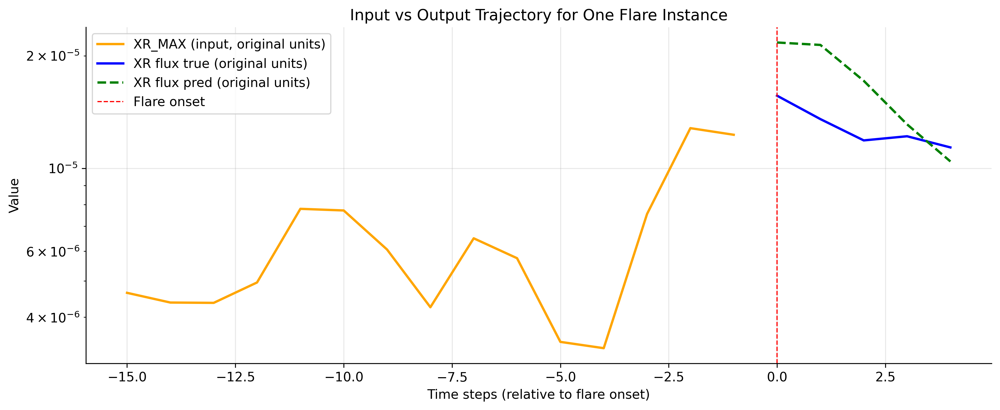

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.0959603e-05, 9.3213530e-06, 6.4886340e-06, 4.2078518e-06,
       2.7343453e-06], dtype=float32), 3) | (array([9.5677e-07, 1.0020e-05, 8.0517e-07, 6.1053e-07, 5.3624e-07]), 3)


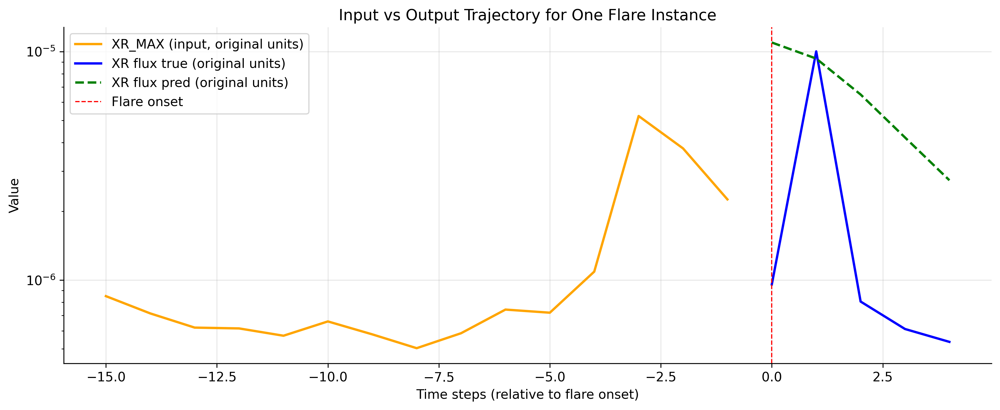

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.6406262e-06, 6.6298044e-06, 4.2668685e-06, 2.5115796e-06,
       1.4010836e-06], dtype=float32), 3) | (array([1.1251e-05, 1.0873e-05, 2.4045e-06, 1.6975e-06, 1.4659e-06]), 3)


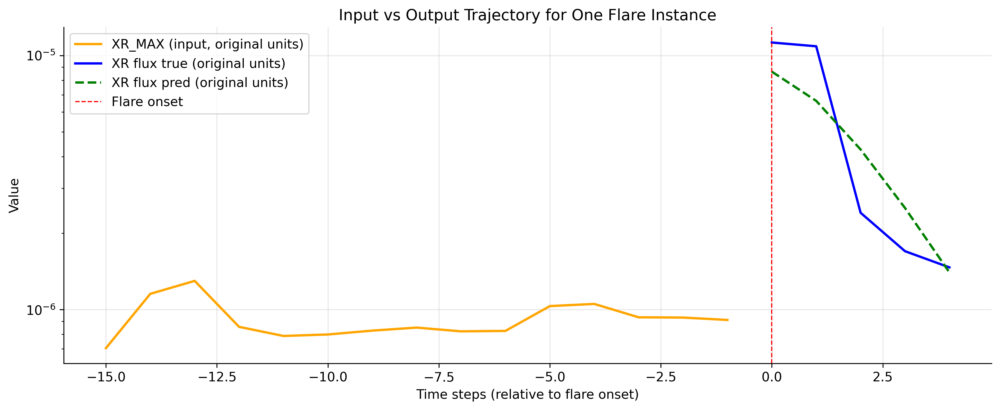

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.1218937e-05, 9.2483651e-06, 6.2294862e-06, 3.8977796e-06,
       2.4216658e-06], dtype=float32), 3) | (array([3.2967e-05, 2.7938e-05, 6.2682e-06, 2.9558e-06, 2.2884e-06]), 3)


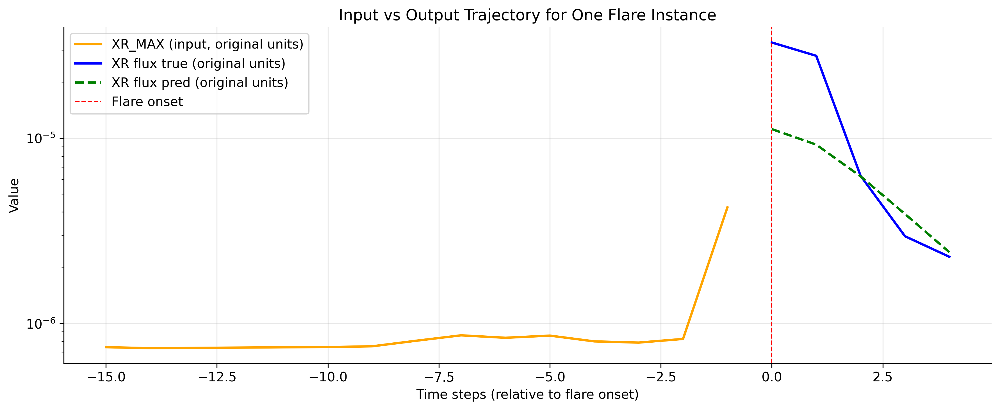

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([9.1303109e-06, 7.2342732e-06, 4.8818479e-06, 3.0910394e-06,
       1.9378672e-06], dtype=float32), 3) | (array([5.8761e-05, 6.5222e-05, 3.2260e-05, 1.2951e-05, 5.2940e-06]), 3)


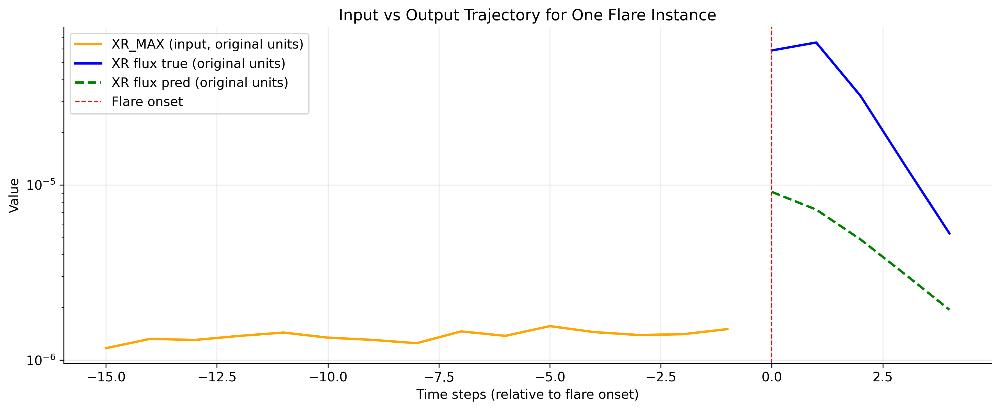

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.04716655e-05, 9.10467315e-06, 7.17870034e-06, 5.55573433e-06,
       4.41380780e-06], dtype=float32), 3) | (array([4.0240e-06, 1.2615e-05, 4.0187e-06, 2.8832e-06, 1.9873e-06]), 3)


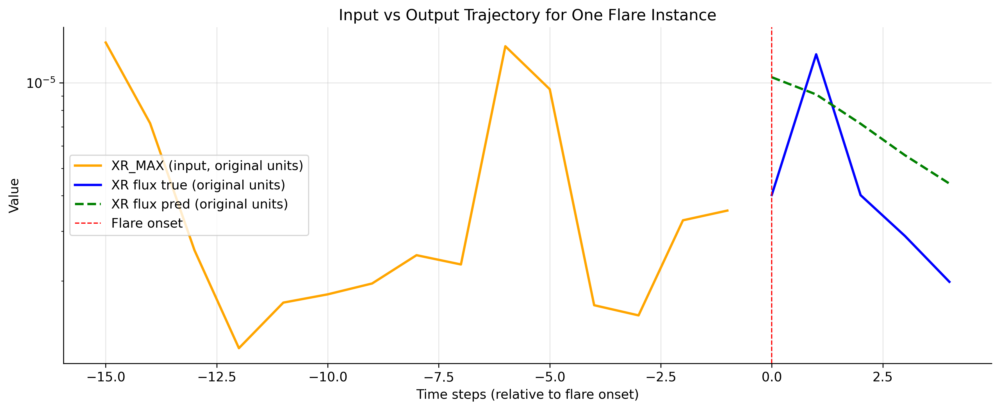

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.2627646e-05, 1.1427943e-05, 9.0127223e-06, 6.8664453e-06,
       5.3630170e-06], dtype=float32), 3) | (array([1.0113e-05, 9.5794e-06, 7.7422e-06, 8.2622e-06, 2.3058e-05]), 3)


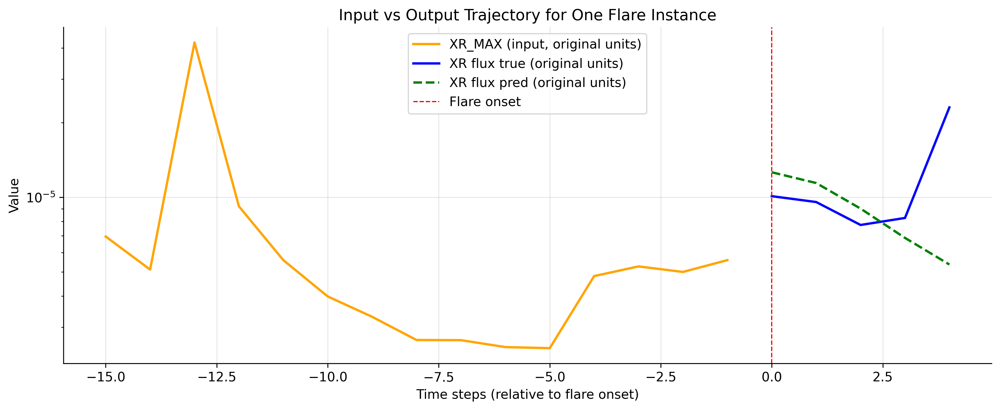

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([2.0115162e-05, 1.9164341e-05, 1.4203630e-05, 9.8819719e-06,
       7.2259099e-06], dtype=float32), 3) | (array([1.6547e-05, 1.6336e-05, 1.2058e-05, 8.5694e-06, 7.8412e-06]), 3)


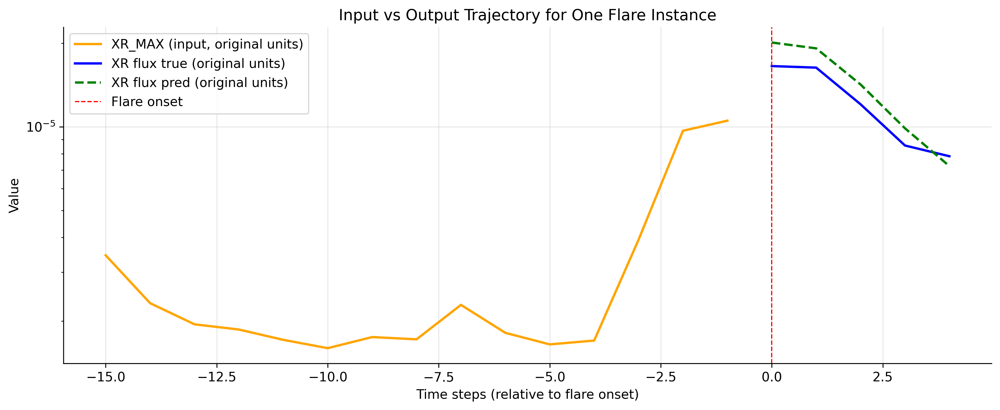

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([6.7310997e-05, 5.6211637e-05, 4.1291132e-05, 3.0505285e-05,
       2.3347633e-05], dtype=float32), 3) | (array([8.7504e-05, 8.6719e-05, 6.4537e-05, 4.7314e-05, 3.2209e-05]), 3)


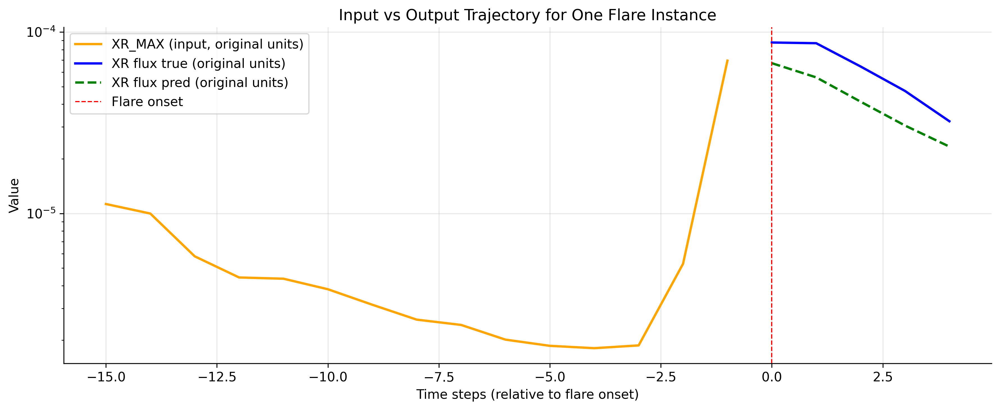

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.0324860e-05, 8.4386420e-06, 5.7686311e-06, 3.7003847e-06,
       2.3697935e-06], dtype=float32), 3) | (array([5.9787e-05, 5.9095e-05, 1.7855e-05, 1.0712e-05, 6.6070e-06]), 3)


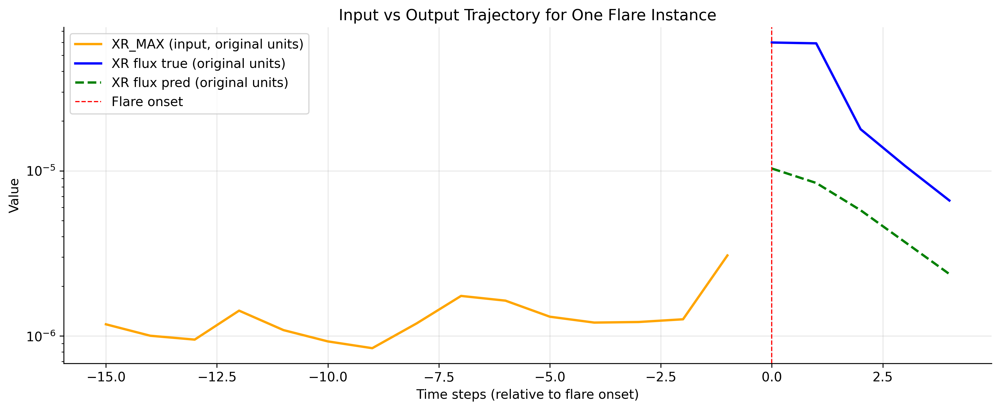

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.7791786e-06, 6.8360646e-06, 4.5220954e-06, 2.7832828e-06,
       1.6722507e-06], dtype=float32), 3) | (array([2.4232e-05, 2.1185e-05, 5.6294e-06, 2.8681e-06, 2.8168e-06]), 3)


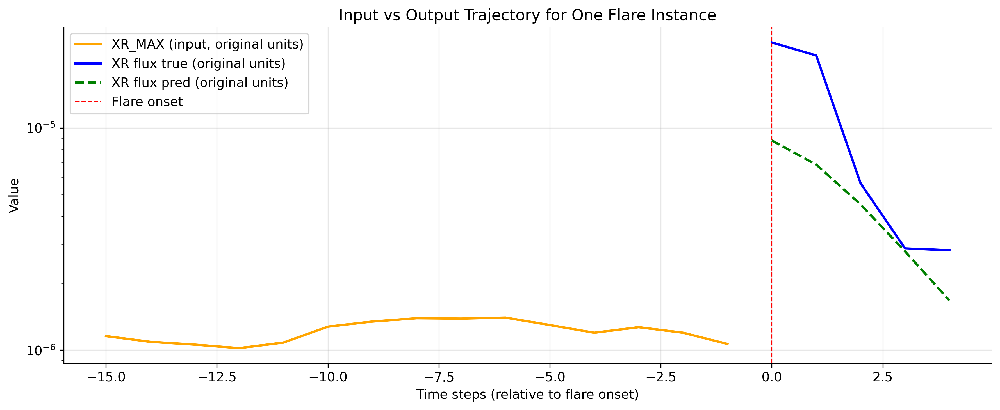

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([6.9423259e-05, 5.8912294e-05, 4.2735963e-05, 3.0406414e-05,
       2.2203030e-05], dtype=float32), 3) | (array([7.9707e-05, 7.9428e-05, 6.9750e-05, 5.8514e-05, 4.6923e-05]), 3)


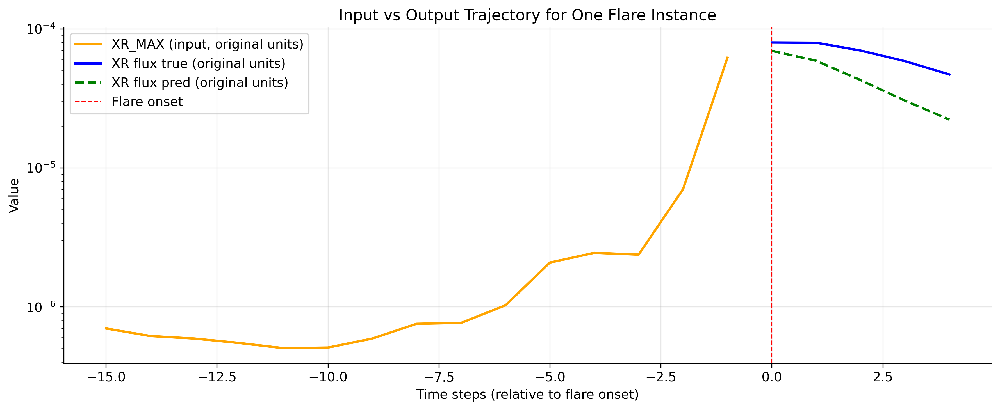

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([2.3880239e-05, 2.3108003e-05, 1.6294629e-05, 1.0692978e-05,
       7.5483590e-06], dtype=float32), 3) | (array([1.2667e-05, 1.1420e-05, 7.2335e-06, 5.0709e-06, 3.5520e-06]), 3)


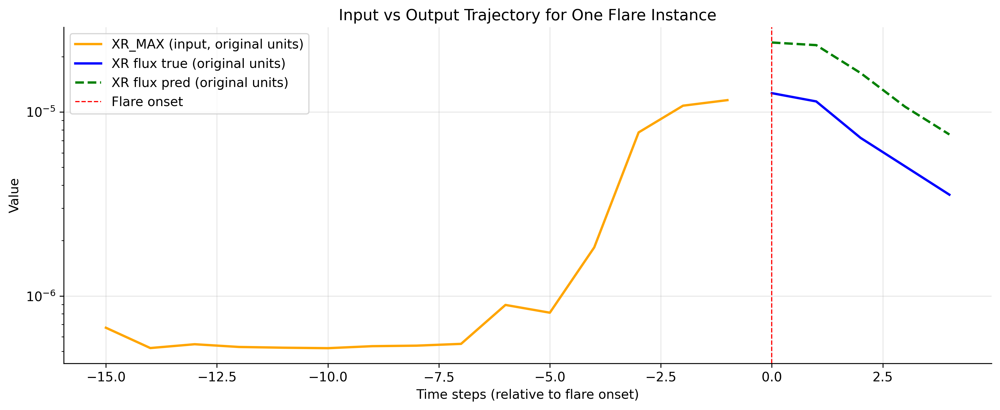

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.9492232e-06, 6.9353755e-06, 4.4825451e-06, 2.6530990e-06,
       1.4956039e-06], dtype=float32), 3) | (array([1.4499e-05, 1.4073e-05, 5.5150e-06, 3.5032e-06, 2.2712e-06]), 3)


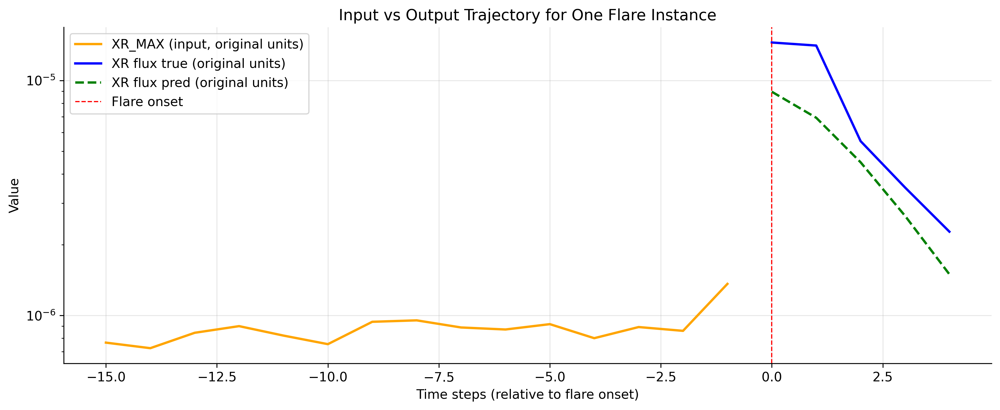

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([6.1399456e-05, 5.1573159e-05, 3.7031205e-05, 2.6748667e-05,
       2.0272953e-05], dtype=float32), 3) | (array([8.2442e-05, 8.4949e-05, 7.8956e-05, 6.9446e-05, 5.4242e-05]), 3)


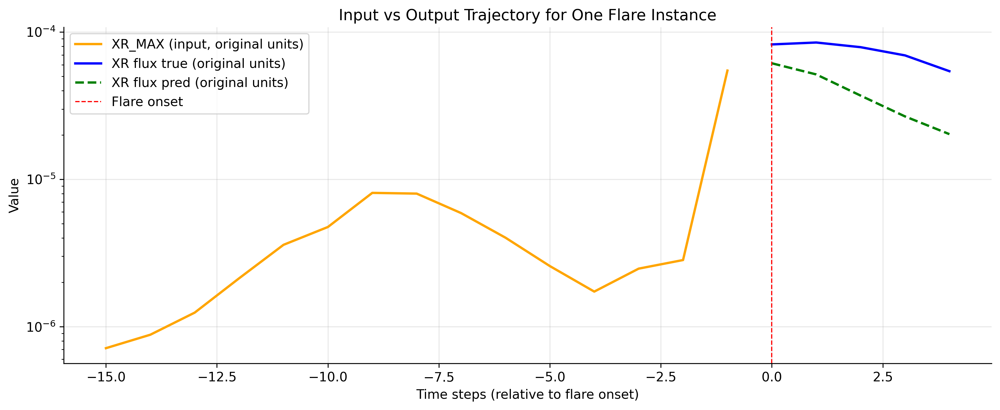

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.2146757e-05, 1.1023253e-05, 8.9734776e-06, 7.1077393e-06,
       5.7434795e-06], dtype=float32), 3) | (array([8.7995e-06, 4.4965e-05, 1.8574e-05, 9.6511e-06, 6.0612e-06]), 3)


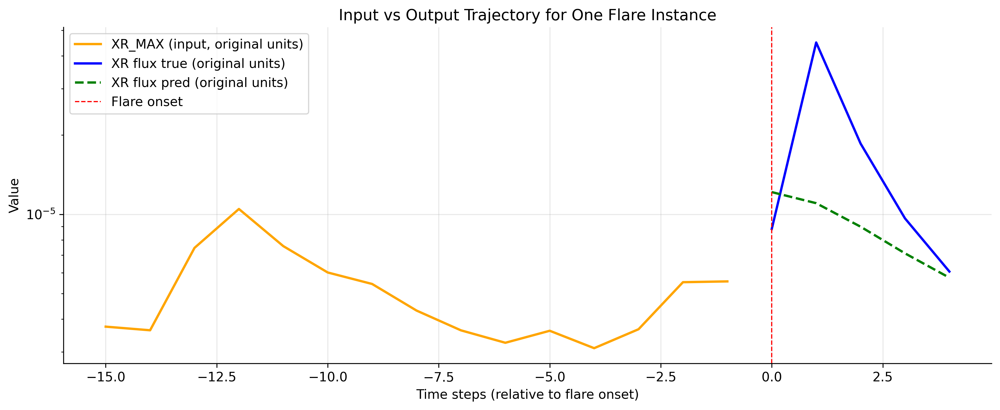

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.1518254e-05, 1.0387442e-05, 8.3373207e-06, 6.5070285e-06,
       5.1948105e-06], dtype=float32), 3) | (array([2.7936e-05, 5.3664e-05, 1.0110e-05, 8.1104e-06, 6.6516e-06]), 3)


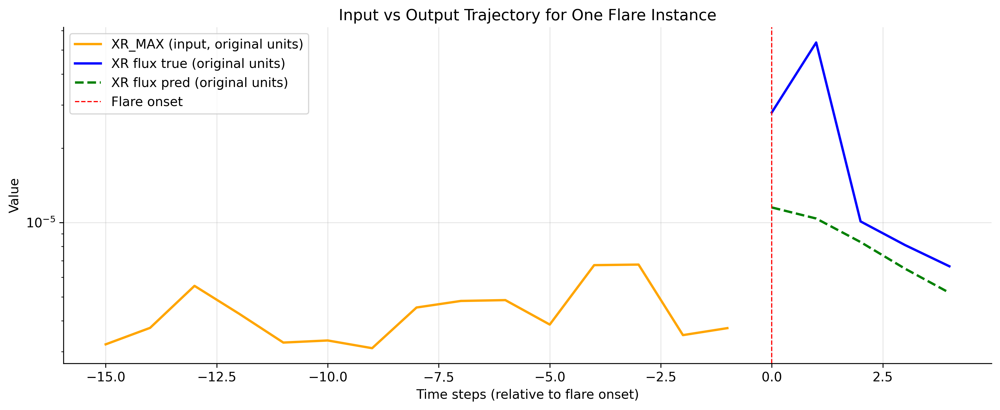

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.0879142e-05, 9.1642687e-06, 6.4034220e-06, 4.2003139e-06,
       2.7717886e-06], dtype=float32), 3) | (array([9.6297e-06, 1.1367e-05, 1.0033e-05, 7.0434e-06, 3.2494e-06]), 3)


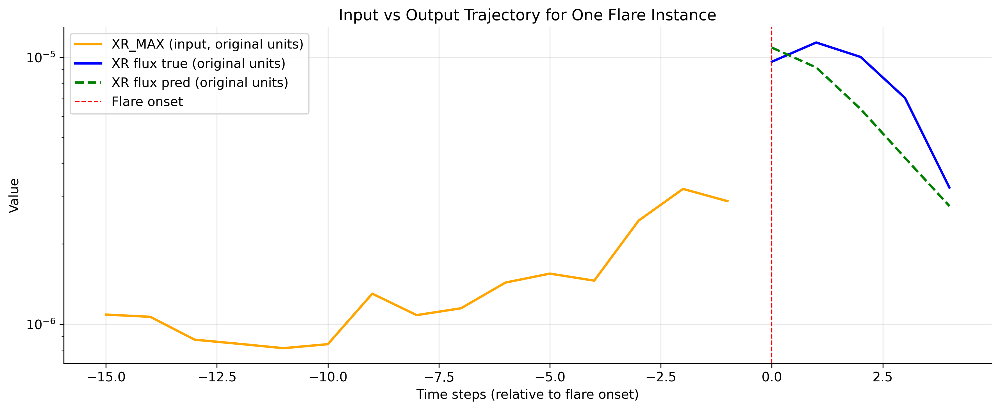

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([6.2066734e-05, 5.7898920e-05, 4.2685249e-05, 3.1171596e-05,
       2.3759172e-05], dtype=float32), 3) | (array([3.2193e-05, 3.2182e-05, 3.1751e-05, 3.0410e-05, 2.8778e-05]), 3)


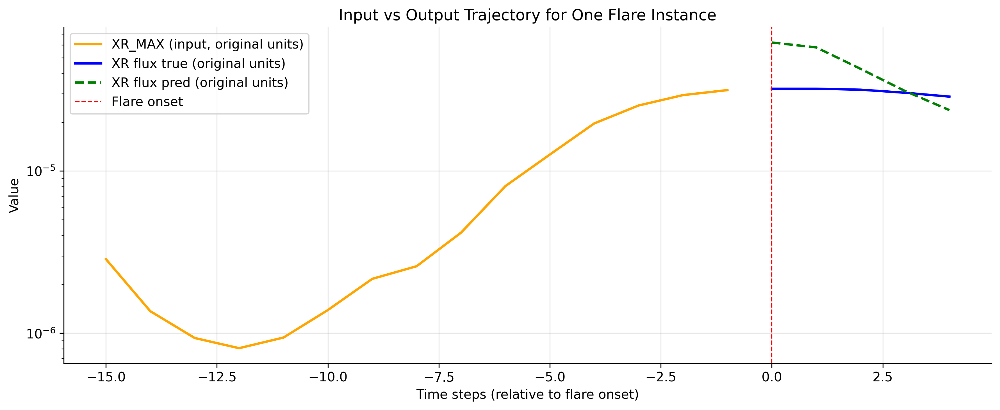

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([2.0628935e-05, 1.8393515e-05, 1.2496792e-05, 7.9895799e-06,
       5.4090829e-06], dtype=float32), 3) | (array([2.8366e-05, 1.8815e-05, 3.5425e-06, 1.7813e-06, 1.1791e-06]), 3)


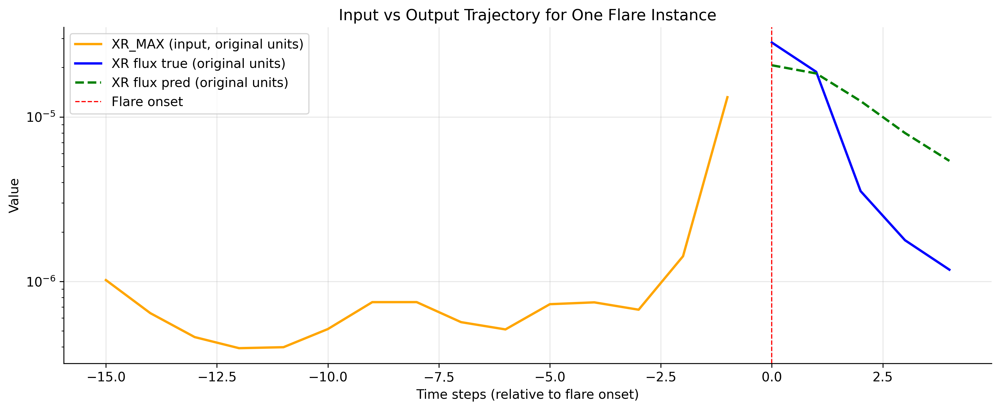

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([9.6072390e-06, 7.9374049e-06, 5.7506290e-06, 4.0102682e-06,
       2.8478962e-06], dtype=float32), 3) | (array([9.7844e-06, 1.3009e-05, 1.0542e-05, 4.9616e-06, 4.4051e-06]), 3)


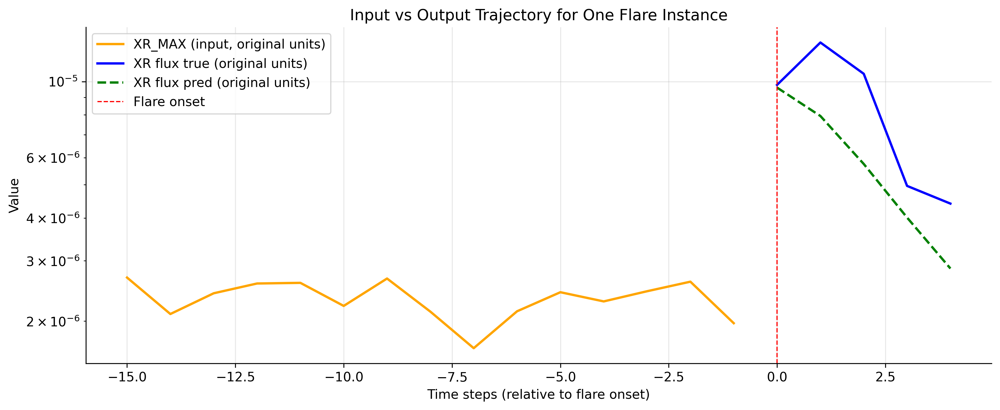

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([2.4457760e-05, 2.2211081e-05, 1.5319134e-05, 1.0084942e-05,
       7.1354616e-06], dtype=float32), 3) | (array([2.1828e-05, 2.1007e-05, 1.4996e-05, 1.1187e-05, 8.9030e-06]), 3)


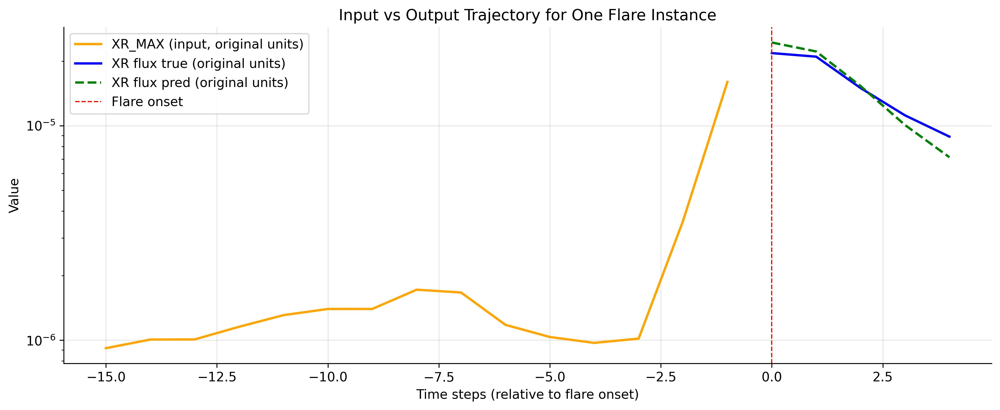

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([5.9469778e-05, 5.1797564e-05, 3.6551137e-05, 2.5446067e-05,
       1.8587323e-05], dtype=float32), 3) | (array([6.5222e-05, 6.4776e-05, 4.9265e-05, 3.0308e-05, 2.0714e-05]), 3)


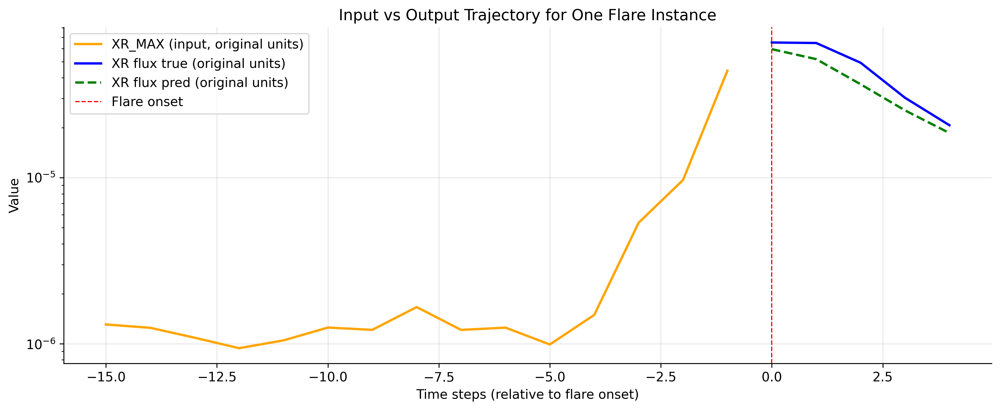

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.1559092e-06, 6.1396413e-06, 3.9804863e-06, 2.3923074e-06,
       1.3854211e-06], dtype=float32), 3) | (array([2.4626e-05, 1.3278e-05, 8.2272e-07, 7.0079e-07, 6.4253e-07]), 3)


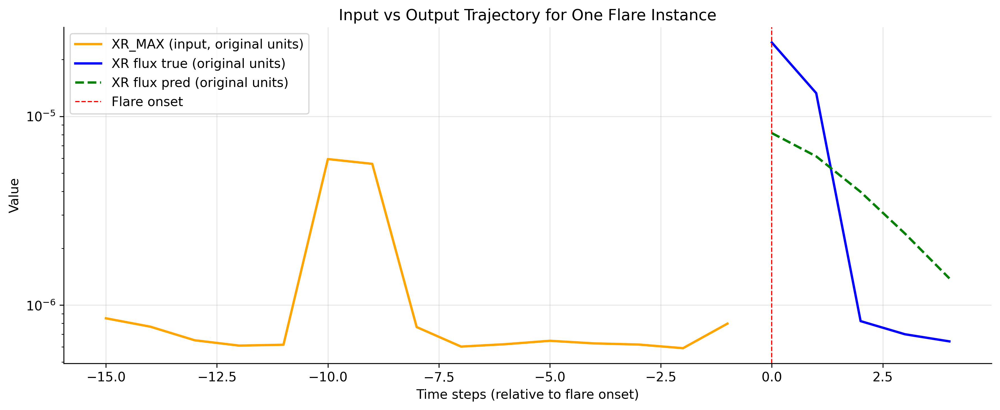

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.8877767e-05, 1.7512499e-05, 1.3675234e-05, 1.0293224e-05,
       8.0340005e-06], dtype=float32), 3) | (array([1.5192e-05, 1.1861e-05, 5.5065e-06, 3.6339e-06, 2.7486e-06]), 3)


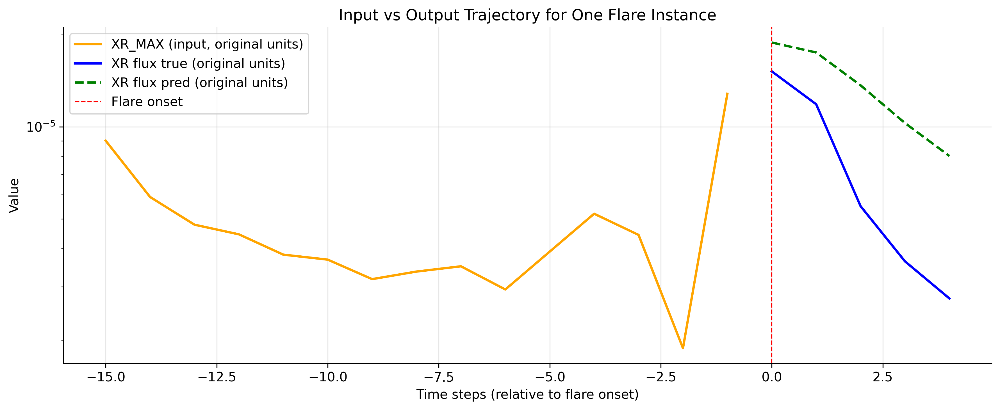

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.4105504e-06, 6.3571651e-06, 4.0423952e-06, 2.3383850e-06,
       1.2641799e-06], dtype=float32), 3) | (array([2.2902e-05, 2.0992e-05, 6.4699e-06, 3.2363e-06, 1.9565e-06]), 3)


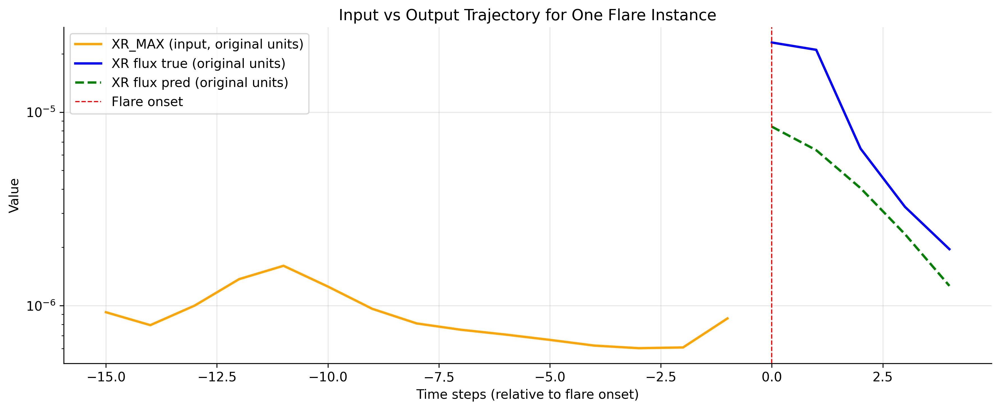

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([8.5253050e-06, 6.4717624e-06, 4.0761438e-06, 2.3123507e-06,
       1.2051909e-06], dtype=float32), 3) | (array([7.4837e-07, 1.3741e-05, 6.9055e-06, 4.1129e-06, 2.4299e-06]), 3)


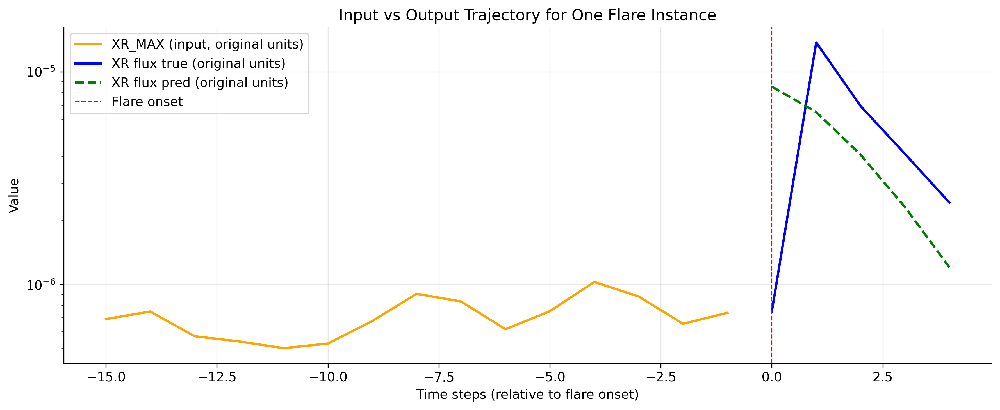

Pred shape: (1, 5, 1)
First 5 preds vs true:
(array([1.2778806e-05, 1.2137854e-05, 1.0632091e-05, 9.1575648e-06,
       8.0241298e-06], dtype=float32), 3) | (array([1.8610e-05, 2.2495e-05, 8.6327e-06, 7.5209e-06, 8.5772e-06]), 3)


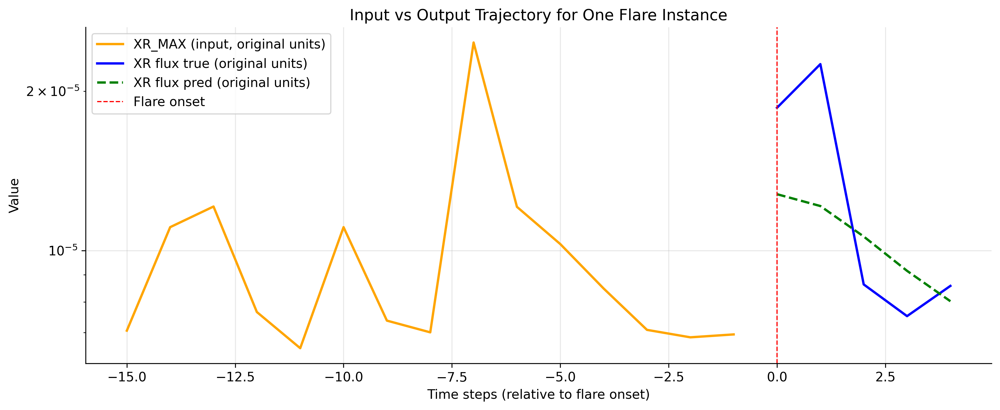

In [29]:
for i in range(len(Y_test_s)): 
    pred_s = predict_autoregressive(encoder_model, decoder_model, X_test_s[i:i+1], H, start_token="last_x_raw", X_raw = X_test[i:i+1], last_x_raw_feature_index=lastfeatureindex, y_scaler = y_scaler, use_log1p = True)
    pred_log   = y_scaler.inverse_transform(pred_s.reshape(-1,1)).reshape(pred_s.shape)
    pred = np.expm1(pred_log)

    true   = Y_test[i:i+1]                                  # already unscaled
    print("Pred shape:", pred.shape)                    # (1, H, 1)
    print("First 5 preds vs true:")
    print((pred[0,:5,0], 3), "|", (true[0,:5,0], 3))
    # Suppose you used:
    # Xm_log = np.log1p(np.clip(Xm, 0, None))
    # x_scaler = StandardScaler().fit(Xm_log_train.reshape(-1, F))
    # y_scaler on log1p(Y), and at prediction you will do inverse -> expm1

    # Build per-feature inverse for X (only for the feature plotted)
    feat_idx = F-1# e.g., XR_MAX column
    def x_inverse_one_feature(arr1d):
        # arr1d is the scaled/logged version for ONE feature
        # We need to invert StandardScaler on that single feature (column feat_idx) and then expm1.
        # Create a temporary 2D array with just this column to use scaler.inverse_transform properly.
        tmp = np.zeros((arr1d.shape[0], F), dtype=float)
        tmp[:, feat_idx] = arr1d
        inv = x_scaler.inverse_transform(tmp)[:, feat_idx]  # back to log-space
        return np.expm1(inv)  # back to original units

    def y_inverse_vec(arr1d):
        # arr1d is the scaled log1p target vector
        inv = y_scaler.inverse_transform(arr1d.reshape(-1,1)).reshape(-1)  # back to log-space
        return np.expm1(inv)  # back to original units

    X_s   = X_test_s[i]          # (L,F) scaled
    Yt_s  = Y_test_s[i]          # (H,) or (H,1) scaled target
    Yp_s  = pred_s           # (H,1) scaled prediction from model.predict

    plot_flare_trajectory(
        X_sample=X_s,
        Y_true=Yt_s,
        Y_pred=Yp_s,
        feature_index=feat_idx,
        x_inverse=x_inverse_one_feature,
        y_inverse=y_inverse_vec,
        input_label="XR_MAX (input, original units)",
        true_label="XR flux true (original units)",
        pred_label="XR flux pred (original units)",
        use_log_y=True
    )

In [30]:
Y_pred_test = predict_autoregressive(encoder_model, decoder_model, X_test_s, H, start_token="last_x_raw", X_raw = X_test, last_x_raw_feature_index=lastfeatureindex, y_scaler = y_scaler, use_log1p = True)
Y_log_test   = y_scaler.inverse_transform(Y_pred_test.reshape(-1,1)).reshape(Y_pred_test.shape)
Y_unscaled_test = np.expm1(Y_log_test)
Y_true_test = Y_test

mean_true = Y_true_test.mean(axis=0)
std_true  = Y_true_test.std(axis=0)
mean_pred = Y_unscaled_test.mean(axis=0)
std_pred  = Y_unscaled_test.std(axis=0)

#convert from 2d to 1d
mean_true = np.asarray(mean_true).ravel()
std_true  = np.asarray(std_true).ravel()
mean_pred = np.asarray(mean_pred).ravel()
std_pred  = np.asarray(std_pred).ravel()

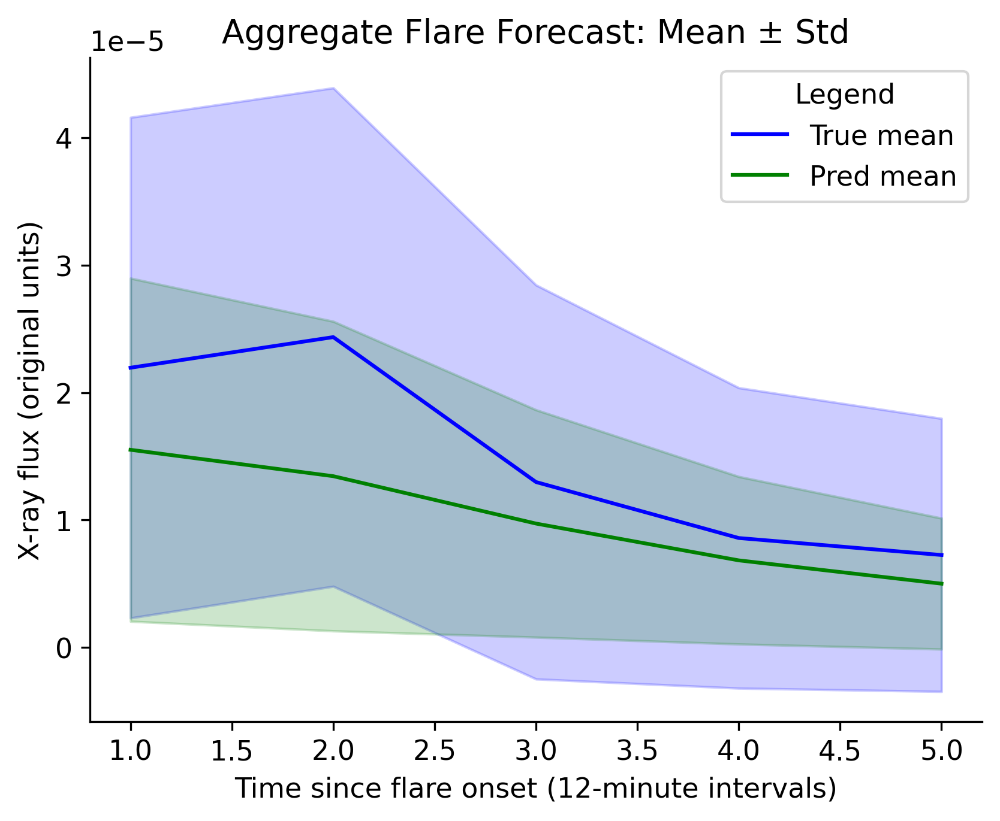

In [31]:
t_output = [1, 2, 3, 4, 5]
plt.plot(t_output, mean_true, color='blue', label='True mean')
plt.fill_between(t_output, mean_true - std_true, mean_true + std_true,
                 color='blue', alpha=0.2)

plt.plot(t_output, mean_pred, color='green', label='Pred mean')
plt.fill_between(t_output, mean_pred - std_pred, mean_pred + std_pred,
                 color='green', alpha=0.2)
plt.xlabel("Time since flare onset (12-minute intervals)")
plt.ylabel("X-ray flux (original units)")   # or whatever unit you use
plt.title("Aggregate Flare Forecast: Mean ± Std")
plt.legend(title="Legend")


In [32]:
#finding rmses
print("min/max true:", Y_true_test.min(), Y_true_test.max())
print("min/max pred:", Y_unscaled_test.min(), Y_unscaled_test.max())
rmse = np.sqrt(np.mean((Y_unscaled_test - Y_true_test)**2))
mae  = np.mean(np.abs(Y_unscaled_test - Y_true_test))

# NRMSE by standard deviation
nrmse_std = rmse / np.std(Y_true_test)

# Log-space RMSE
log_rmse = np.sqrt(
    np.mean((np.log1p(Y_unscaled_test) - np.log1p(Y_true_test))**2)
)

print("rmse: " + str(rmse))
print("mae: " + str(mae))
print("nrmse_std: " + str(nrmse_std))
print("log_rmse: " + str(log_rmse))

true_log10 = np.log10(Y_true_test)
pred_log10 = np.log10(Y_unscaled_test)

rmse_log10 = np.sqrt(np.mean((pred_log10 - true_log10)**2))
print("RMSE (log10 flux):", rmse_log10)

min/max true: 2.1754e-07 8.7504e-05
min/max pred: 7.099787e-07 6.942326e-05
rmse: 1.3996128824445502e-05
mae: 8.001292039972575e-06
nrmse_std: 0.8071840878150558
log_rmse: 1.3995670543772821e-05
RMSE (log10 flux): 0.3761354226118209


In [33]:
Yt = np.asarray(Y_true_test).ravel()
Yp = np.asarray(Y_unscaled_test).ravel()

# remove NaNs if any
mask = np.isfinite(Yt) & np.isfinite(Yp)
Yt = Yt[mask]
Yp = Yp[mask]

# standard deviations
sigma_obs = np.std(Yt, ddof=1)
sigma_mod = np.std(Yp, ddof=1)

# correlation
corr = np.corrcoef(Yt, Yp)[0, 1]
theta = np.arccos(corr) 

# centered RMSE (for info, not needed to place the point)
crmsd = np.sqrt(np.mean(((Yp - Yp.mean()) - (Yt - Yt.mean()))**2))

In [34]:
#persistence model
Y_persistence = np.repeat(X_test[:,14,lastfeatureindex].reshape(len(X_test), 1), H, axis=1)
Y_persistence = np.asarray(Y_persistence).ravel()
Y_persistence

array([5.7945e-06, 5.7945e-06, 5.7945e-06, 5.7945e-06, 5.7945e-06,
       7.1635e-06, 7.1635e-06, 7.1635e-06, 7.1635e-06, 7.1635e-06,
       4.2682e-06, 4.2682e-06, 4.2682e-06, 4.2682e-06, 4.2682e-06,
       1.7575e-06, 1.7575e-06, 1.7575e-06, 1.7575e-06, 1.7575e-06,
       4.8863e-07, 4.8863e-07, 4.8863e-07, 4.8863e-07, 4.8863e-07,
       4.7084e-07, 4.7084e-07, 4.7084e-07, 4.7084e-07, 4.7084e-07,
       5.1785e-06, 5.1785e-06, 5.1785e-06, 5.1785e-06, 5.1785e-06,
       2.9004e-06, 2.9004e-06, 2.9004e-06, 2.9004e-06, 2.9004e-06,
       2.4831e-06, 2.4831e-06, 2.4831e-06, 2.4831e-06, 2.4831e-06,
       9.0600e-06, 9.0600e-06, 9.0600e-06, 9.0600e-06, 9.0600e-06,
       1.8118e-06, 1.8118e-06, 1.8118e-06, 1.8118e-06, 1.8118e-06,
       1.6158e-05, 1.6158e-05, 1.6158e-05, 1.6158e-05, 1.6158e-05,
       8.2444e-07, 8.2444e-07, 8.2444e-07, 8.2444e-07, 8.2444e-07,
       1.7200e-06, 1.7200e-06, 1.7200e-06, 1.7200e-06, 1.7200e-06,
       1.5788e-06, 1.5788e-06, 1.5788e-06, 1.5788e-06, 1.5788e

In [35]:
def taylor_diagram_one_quadrant(Y_true_all,
                                Y_model_all,
                                Y_pers_all=None,
                                model_label="LSTM model",
                                pers_label="Persistence"):
    """
    Y_true_all, Y_model_all, Y_pers_all: arrays of shape (N, H) in original units.
    Builds a one-quadrant Taylor diagram (correlation 0..1).
    """
    # flatten all time steps and samples
    Yt = np.asarray(Y_true_all).ravel()
    Ym = np.asarray(Y_model_all).ravel()

    mask_m = np.isfinite(Yt) & np.isfinite(Ym)
    Yt_m = Yt[mask_m]
    Ym_m = Ym[mask_m]

    # stats for model
    sigma_obs = np.std(Yt_m, ddof=1)
    sigma_mod = np.std(Ym_m, ddof=1)
    corr_mod = np.corrcoef(Yt_m, Ym_m)[0, 1]

    # optional persistence stats
    sigma_pers = None
    corr_pers = None
    if Y_pers_all is not None:
        Yp = np.asarray(Y_pers_all).ravel()
        mask_p = np.isfinite(Yt) & np.isfinite(Yp)
        Yt_p = Yt[mask_p]
        Yp_p = Yp[mask_p]

        sigma_pers = np.std(Yp_p, ddof=1)
        corr_pers = np.corrcoef(Yt_p, Yp_p)[0, 1]

    print("Observation std:", sigma_obs)
    print("Model std:", sigma_mod, "corr:", corr_mod)
    if sigma_pers is not None:
        print("Persistence std:", sigma_pers, "corr:", corr_pers)

    # angle = arccos(correlation), correlation in [0,1] gives theta in [0, pi/2]
    theta_mod = np.arccos(np.clip(corr_mod, 0, 1))
    theta_pers = None
    if corr_pers is not None:
        theta_pers = np.arccos(np.clip(corr_pers, 0, 1))

    # radial limit a bit larger than max std among obs, model, persistence
    stds = [sigma_obs, sigma_mod]
    if sigma_pers is not None:
        stds.append(sigma_pers)
    rmax = 1.2 * max(stds)

    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111, polar=True)

    # one quadrant only: theta from 0 to pi/2
    ax.set_thetamin(0)
    ax.set_thetamax(90)

    # radial limits
    ax.set_rlim(0, rmax)

    # reference point (observations) at angle = 0, radius = sigma_obs
    ax.plot(0, sigma_obs, "ko", label="Observations")

    # model point
    ax.plot(theta_mod, sigma_mod, "ro", label=model_label)

    # persistence point if provided
    if theta_pers is not None:
        ax.plot(theta_pers, sigma_pers, "bo", label=pers_label)

    # correlation guide lines
    corr_ticks = [0.2, 0.4, 0.6, 0.8, 0.9, 0.95]
    for c in corr_ticks:
        if 0 <= c <= 1:
            t = np.arccos(c)
            ax.plot([t, t], [0, rmax], color="lightgray", linewidth=0.8)
            ax.text(t, rmax * 1.02, f"{c:.2f}",
                    ha="center", va="bottom", fontsize=8)

    # radial ticks as standard deviation
    rticks = np.linspace(0, rmax, 4)
    ax.set_yticks(rticks)
    ax.set_yticklabels([f"{v:.2g}" for v in rticks])

    ax.set_title("Taylor diagram (one quadrant)")
    ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1))
    plt.tight_layout()
    plt.show()


Observation std: 1.735832887266332e-05
Model std: 1.0553356e-05 corr: 0.6569019762276377
Persistence std: 1.2426843304128686e-05 corr: 0.6210689160624002


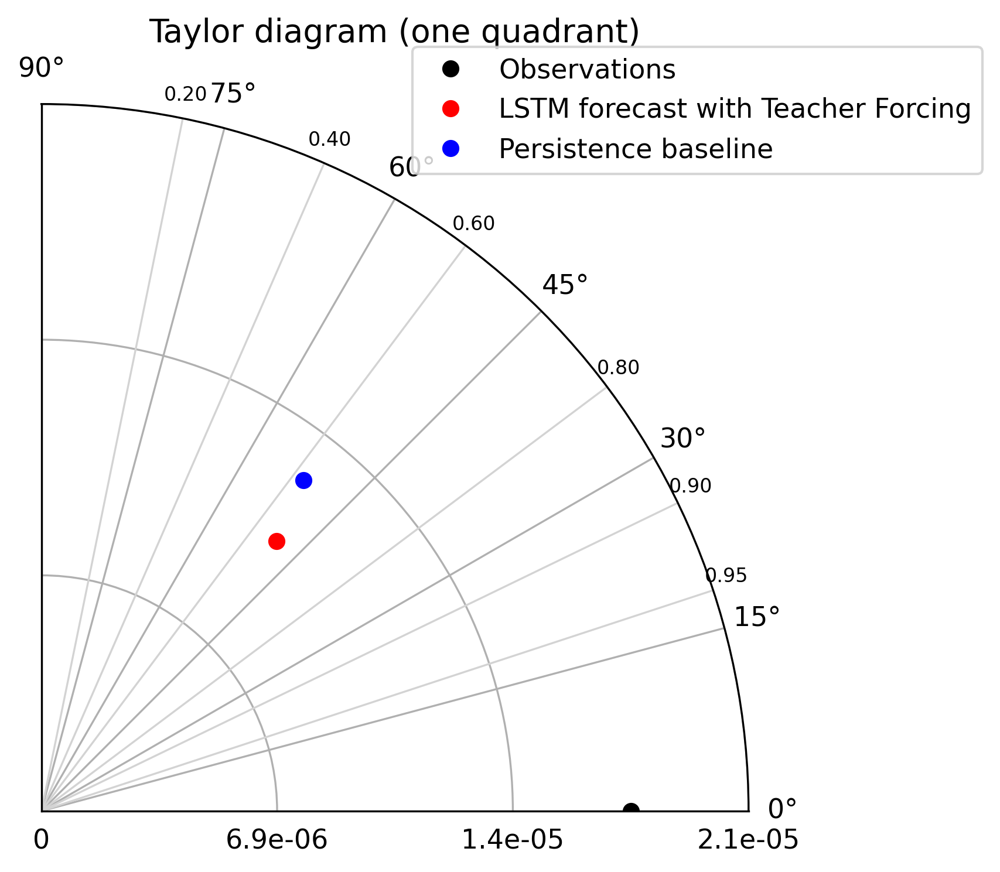

In [36]:
taylor_diagram_one_quadrant(Y_true_test, Y_unscaled_test, Y_persistence, model_label="LSTM forecast with Teacher Forcing", pers_label="Persistence baseline")

In [37]:
def measure_ar_time(run_fn, warmup=3, n_runs=30):

    # Warmup
    for _ in range(warmup):
        _ = run_fn()

    times = []

    for _ in range(n_runs):
        t0 = time.perf_counter()
        _ = run_fn()
        t1 = time.perf_counter()
        times.append(t1 - t0)

    times = np.array(times)

    print(f"Mean AR inference time: {times.mean()*1000:.3f} ms")
    print(f"Std: {times.std()*1000:.3f} ms")
    print(f"Min: {times.min()*1000:.3f} ms")
    print(f"Max: {times.max()*1000:.3f} ms")

    return times

In [38]:
i = 0
X_in = X_test_s[i:i+1]   # shape (1, L, F)
X_raw_in = X_test[i:i+1] # matching raw version if your function needs it

def run_once():
    return predict_autoregressive(
        encoder_model, decoder_model, X_in, H,
        start_token="last_x_raw",
        X_raw=X_raw_in,
        last_x_raw_feature_index=lastfeatureindex,
        y_scaler=y_scaler,
        use_log1p=True
    )

measure_ar_time(run_once, warmup=5, n_runs=50)

Mean AR inference time: 585.293 ms
Std: 9.655 ms
Min: 572.975 ms
Max: 614.636 ms


array([0.61463587, 0.6037477 , 0.58775925, 0.57380862, 0.57882883,
       0.57297458, 0.58042938, 0.5794222 , 0.58045629, 0.57828193,
       0.57497291, 0.58081022, 0.57969932, 0.60930053, 0.59120717,
       0.57874277, 0.59549319, 0.57785629, 0.58944693, 0.58612726,
       0.57888363, 0.59442343, 0.58846832, 0.5889157 , 0.58079241,
       0.58211254, 0.58182499, 0.57583695, 0.58050426, 0.57815648,
       0.59734458, 0.59614035, 0.59070442, 0.5851516 , 0.59370073,
       0.58540524, 0.5944212 , 0.58806115, 0.58610671, 0.57872517,
       0.58069261, 0.57950026, 0.58271401, 0.57602433, 0.57794282,
       0.57368592, 0.57900227, 0.58285328, 0.61261535, 0.57992796])

In [39]:
#saving model
model.save("/kaggle/working/model"+str(rmse_log10)+".keras")